# BÀI TẬP LỚN HỌC PHẦN NHẬP MÔN HỌC MÁY (FIT4013)
## Đề tài 13: Dự đoán nhân viên có khả năng nghỉ việc (Employee Attrition Prediction)
- **Nhóm đề tài:** Dữ liệu dạng bảng (*Tabular Data*)
- **Giảng viên hướng dẫn:** ThS. Lê Thị Thùy Trang
- **Nhóm thực hiện:** **Nhóm 7**
  1. **Nguyễn Văn An** – MSSV: `1871020003`
  2. **Nguyễn Việt Anh** – MSSV: `1871020047`
  3. **Đào Thị Tươi** – MSSV: `1871020639`
  4. **Lê Đình Huy** – MSSV: `1871020307`

---
## Mở Đầu: Giới Thiệu Bài Toán & Mục Tiêu Nghiên Cứu
- **Đặt vấn đề:** Tình trạng biến động nhân sự tự nguyện (*Employee Attrition*) gây tổn thất lớn cho doanh nghiệp về chi phí tuyển dụng, đào tạo lại và gián đoạn vận hành. Việc xây dựng mô hình Học máy dự báo sớm những nhân viên có nguy cơ nghỉ việc giúp bộ phận Nhân sự (HR) chủ động can thiệp và cải thiện chính sách giữ chân nhân tài.
- **Bộ dữ liệu:** *IBM HR Analytics Employee Attrition & Performance* gồm **1,470 hồ sơ nhân viên** với **35 thuộc tính** phản ánh thông tin nhân khẩu học, chế độ đãi ngộ, môi trường làm việc và lộ trình thăng tiến. Biến mục tiêu là `Attrition` (`Yes`: nghỉ việc – `16.12%`, `No`: ở lại – `83.88%`).
- **Mục tiêu thực nghiệm:**
  1. Phân tích khám phá dữ liệu (EDA) và kiểm định thống kê để xác định các yếu tố cốt lõi dẫn đến quyết định nghỉ việc.
  2. Thiết kế và đối sánh hai luồng chuẩn bị dữ liệu độc lập: **Luồng A (Pipeline cơ bản)** và **Luồng B (Pipeline cải tiến có kỹ thuật tạo đặc trưng nghiệp vụ HR)**.
  3. Huấn luyện, tinh chỉnh siêu tham số và đánh giá khách quan các thuật toán **K-Nearest Neighbors (`K-NN`)**, **Gaussian Naive Bayes**, **Decision Tree** cùng phương pháp mở rộng **Random Forest**, hướng tới tối ưu hóa `F1-Score`, `Recall` và `ROC-AUC` trên lớp thiểu số.

In [1]:
# PHẦN 0: KHỞI TẠO MÔI TRƯỜNG & CẤU HÌNH TÁI LẬP (REPRODUCIBILITY)
import os
import sys
import joblib
import warnings
warnings.filterwarnings('ignore')
os.environ['LOKY_MAX_CPU_COUNT'] = '4'

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve
)

# Cố định RANDOM_STATE trên toàn bộ pipeline
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

FIG_DIR = '../report/figures' if os.path.exists('../report') else 'report/figures'
MODEL_DIR = '../models' if os.path.exists('../models') else 'models'
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)
DATA_PATH = '../data/WA_Fn-UseC_-HR-Employee-Attrition.csv' if os.path.exists('../data/WA_Fn-UseC_-HR-Employee-Attrition.csv') else 'data/WA_Fn-UseC_-HR-Employee-Attrition.csv'

df = pd.read_csv(DATA_PATH)
print(f"Đã tải dữ liệu thành công! Kích thước: {df.shape[0]} bản ghi x {df.shape[1]} thuộc tính.")
print(f"Phân loại kiểu dữ liệu: {dict(df.dtypes.value_counts())}")

Đã tải dữ liệu thành công! Kích thước: 1470 bản ghi x 35 thuộc tính.
Phân loại kiểu dữ liệu: {dtype('int64'): 26, dtype('O'): 9}


---
## Phần 1: Khám Phá và Phân Tích Dữ Liệu Chuyên Sâu (EDA)
### 1.1. Kiểm tra cấu trúc bảng dữ liệu và Từ điển giải thích toàn bộ 35 thuộc tính

In [2]:
# 1.1. Hiển thị 5 bản ghi đầu tiên và lập bảng từ điển dữ liệu giải thích ý nghĩa 35 cột
col_descriptions = [
    ("Age", "int64", "Số liên tục", "Tuổi của nhân viên (18 - 60 tuổi)"),
    ("Attrition", "object", "Mục tiêu (Nhị phân)", "Nhân viên có nghỉ việc hay không (Yes / No)"),
    ("BusinessTravel", "object", "Phân loại (Thứ bậc)", "Tần suất đi công tác (Non-Travel, Travel_Rarely, Travel_Frequently)"),
    ("DailyRate", "int64", "Số liên tục", "Mức lương quy chiếu theo ngày (102 - 1499)"),
    ("Department", "object", "Phân loại định danh", "Phòng ban làm việc (Sales, Research & Development, Human Resources)"),
    ("DistanceFromHome", "int64", "Số liên tục", "Khoảng cách từ nhà đến công ty (1 - 29 dặm)"),
    ("Education", "int64", "Thứ bậc (1-5)", "Trình độ học vấn (1: Below College, 2: College, 3: Bachelor, 4: Master, 5: Doctor)"),
    ("EducationField", "object", "Phân loại định danh", "Chuyên ngành đào tạo (Life Sciences, Medical, Marketing, Technical Degree...)"),
    ("EmployeeCount", "int64", "Hằng số (=1)", "Số lượng nhân viên trên mỗi bản ghi (luôn bằng 1 -> Cần loại bỏ)"),
    ("EmployeeNumber", "int64", "Định danh (ID)", "Mã định danh duy nhất của nhân viên (1 - 2068 -> Cần loại bỏ)"),
    ("EnvironmentSatisfaction", "int64", "Thứ bậc (1-4)", "Mức độ hài lòng với môi trường làm việc (1: Low -> 4: Very High)"),
    ("Gender", "object", "Phân loại nhị phân", "Giới tính (Male / Female)"),
    ("HourlyRate", "int64", "Số liên tục", "Mức lương quy chiếu theo giờ (30 - 100)"),
    ("JobInvolvement", "int64", "Thứ bậc (1-4)", "Mức độ gắn kết/tham gia vào công việc (1: Low -> 4: Very High)"),
    ("JobLevel", "int64", "Thứ bậc (1-5)", "Cấp bậc công việc trong tổ chức (1: Nhân viên mới -> 5: Giám đốc/Cấp cao)"),
    ("JobRole", "object", "Phân loại định danh", "Chức danh công việc cụ thể (9 chức danh: Sales Executive, Research Scientist...)"),
    ("JobSatisfaction", "int64", "Thứ bậc (1-4)", "Mức độ hài lòng với công việc hiện tại (1: Low -> 4: Very High)"),
    ("MaritalStatus", "object", "Phân loại định danh", "Tình trạng hôn nhân (Single, Married, Divorced)"),
    ("MonthlyIncome", "int64", "Số liên tục", "Thu nhập thực tế hàng tháng bằng USD (1,009 - 19,999)"),
    ("MonthlyRate", "int64", "Số liên tục", "Mức lương quy chiếu theo tháng (2,094 - 26,999)"),
    ("NumCompaniesWorked", "int64", "Số rời rạc", "Tổng số công ty nhân viên từng làm việc trước đây (0 - 9)"),
    ("Over18", "object", "Hằng số (='Y')", "Nhân viên trên 18 tuổi hay không (luôn là 'Y' -> Cần loại bỏ)"),
    ("OverTime", "object", "Phân loại nhị phân", "Nhân viên có làm thêm giờ hay không (Yes / No)"),
    ("PercentSalaryHike", "int64", "Số liên tục", "Tỷ lệ phần trăm tăng lương gần nhất (11% - 25%)"),
    ("PerformanceRating", "int64", "Thứ bậc (3-4)", "Điểm đánh giá hiệu suất làm việc (3: Excellent, 4: Outstanding)"),
    ("RelationshipSatisfaction", "int64", "Thứ bậc (1-4)", "Mức độ hài lòng với các mối quan hệ đồng nghiệp/quản lý (1 - 4)"),
    ("StandardHours", "int64", "Hằng số (=80)", "Số giờ làm việc tiêu chuẩn trong kỳ (luôn bằng 80 -> Cần loại bỏ)"),
    ("StockOptionLevel", "int64", "Thứ bậc (0-3)", "Mức quyền chọn mua cổ phiếu ưu đãi của công ty (0 - 3)"),
    ("TotalWorkingYears", "int64", "Số liên tục", "Tổng số năm kinh nghiệm đi làm trong sự nghiệp (0 - 40 năm)"),
    ("TrainingTimesLastYear", "int64", "Số rời rạc", "Số lần tham gia khóa đào tạo trong năm ngoái (0 - 6 lần)"),
    ("WorkLifeBalance", "int64", "Thứ bậc (1-4)", "Mức độ cân bằng giữa công việc và cuộc sống (1: Bad -> 4: Best)"),
    ("YearsAtCompany", "int64", "Số liên tục", "Tổng số năm làm việc tại công ty hiện tại (0 - 40 năm)"),
    ("YearsInCurrentRole", "int64", "Số liên tục", "Số năm giữ vị trí công việc hiện tại (0 - 18 năm)"),
    ("YearsSinceLastPromotion", "int64", "Số liên tục", "Số năm kể từ lần được thăng chức gần nhất (0 - 15 năm)"),
    ("YearsWithCurrManager", "int64", "Số liên tục", "Số năm làm việc dưới quyền người quản lý hiện tại (0 - 17 năm)")
]
col_dict_df = pd.DataFrame(col_descriptions, columns=["Tên cột", "Kiểu dữ liệu", "Bản chất", "Ý nghĩa chi tiết"])
display(df.head(5))
display(col_dict_df)

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


,Tên cột,Kiểu dữ liệu,Bản chất,Ý nghĩa chi tiết
0,Age,int64,Số liên tục,Tuổi của nhân viên (18 - 60 tuổi)
1,Attrition,object,Mục tiêu (Nhị phân),Nhân viên có nghỉ việc hay không (Yes / No)
2,BusinessTravel,object,Phân loại (Thứ bậc),"Tần suất đi công tác (Non-Travel, Travel_Rarely, Travel_Frequently)"
3,DailyRate,int64,Số liên tục,Mức lương quy chiếu theo ngày (102 - 1499)
4,Department,object,Phân loại định danh,"Phòng ban làm việc (Sales, Research & Development, Human Resources)"
5,DistanceFromHome,int64,Số liên tục,Khoảng cách từ nhà đến công ty (1 - 29 dặm)
6,Education,int64,Thứ bậc (1-5),"Trình độ học vấn (1: Below College, 2: College, 3: Bachelor, 4: Master, 5: Doctor)"
7,EducationField,object,Phân loại định danh,"Chuyên ngành đào tạo (Life Sciences, Medical, Marketing, Technical Degree...)"
8,EmployeeCount,int64,Hằng số (=1),Số lượng nhân viên trên mỗi bản ghi (luôn bằng 1 -> Cần loại bỏ)
9,EmployeeNumber,int64,Định danh (ID),Mã định danh duy nhất của nhân viên (1 - 2068 -> Cần loại bỏ)


### 1.2. Kiểm tra dữ liệu thiếu, trùng lặp, cột hằng số (phương sai bằng 0) và cột định danh

In [3]:
# 1.2. Kiểm tra tính toàn vẹn của dữ liệu (Missing, Duplicates, Zero-Variance, ID)
null_total = df.isnull().sum().sum()
dup_total = df.duplicated().sum()
const_cols = [c for c in df.columns if df[c].nunique() <= 1]
id_cols = [c for c in df.columns if df[c].nunique() == len(df)]

print(f"1. Tổng số giá trị bị khuyết (Missing values): {null_total}")
print(f"2. Tổng số bản ghi trùng lặp (Duplicates)    : {dup_total}")
print(f"3. Các cột hằng số (Zero-variance columns)  : {const_cols}")
for c in const_cols:
    print(f"   - {c}: chỉ nhận giá trị {df[c].unique().tolist()}")
print(f"4. Các cột định danh duy nhất (ID columns)  : {id_cols} ({df['EmployeeNumber'].nunique()} mã riêng biệt)")

1. Tổng số giá trị bị khuyết (Missing values): 0
2. Tổng số bản ghi trùng lặp (Duplicates)    : 0
3. Các cột hằng số (Zero-variance columns)  : ['EmployeeCount', 'Over18', 'StandardHours']
   - EmployeeCount: chỉ nhận giá trị [1]
   - Over18: chỉ nhận giá trị ['Y']
   - StandardHours: chỉ nhận giá trị [80]
4. Các cột định danh duy nhất (ID columns)  : ['EmployeeNumber'] (1470 mã riêng biệt)


### 1.3. Phân tích biến mục tiêu `Attrition` (Mất cân bằng lớp 83.88% vs 16.12%)

,Số lượng nhân viên,Tỷ lệ (%)
No,1233,83.88
Yes,237,16.12


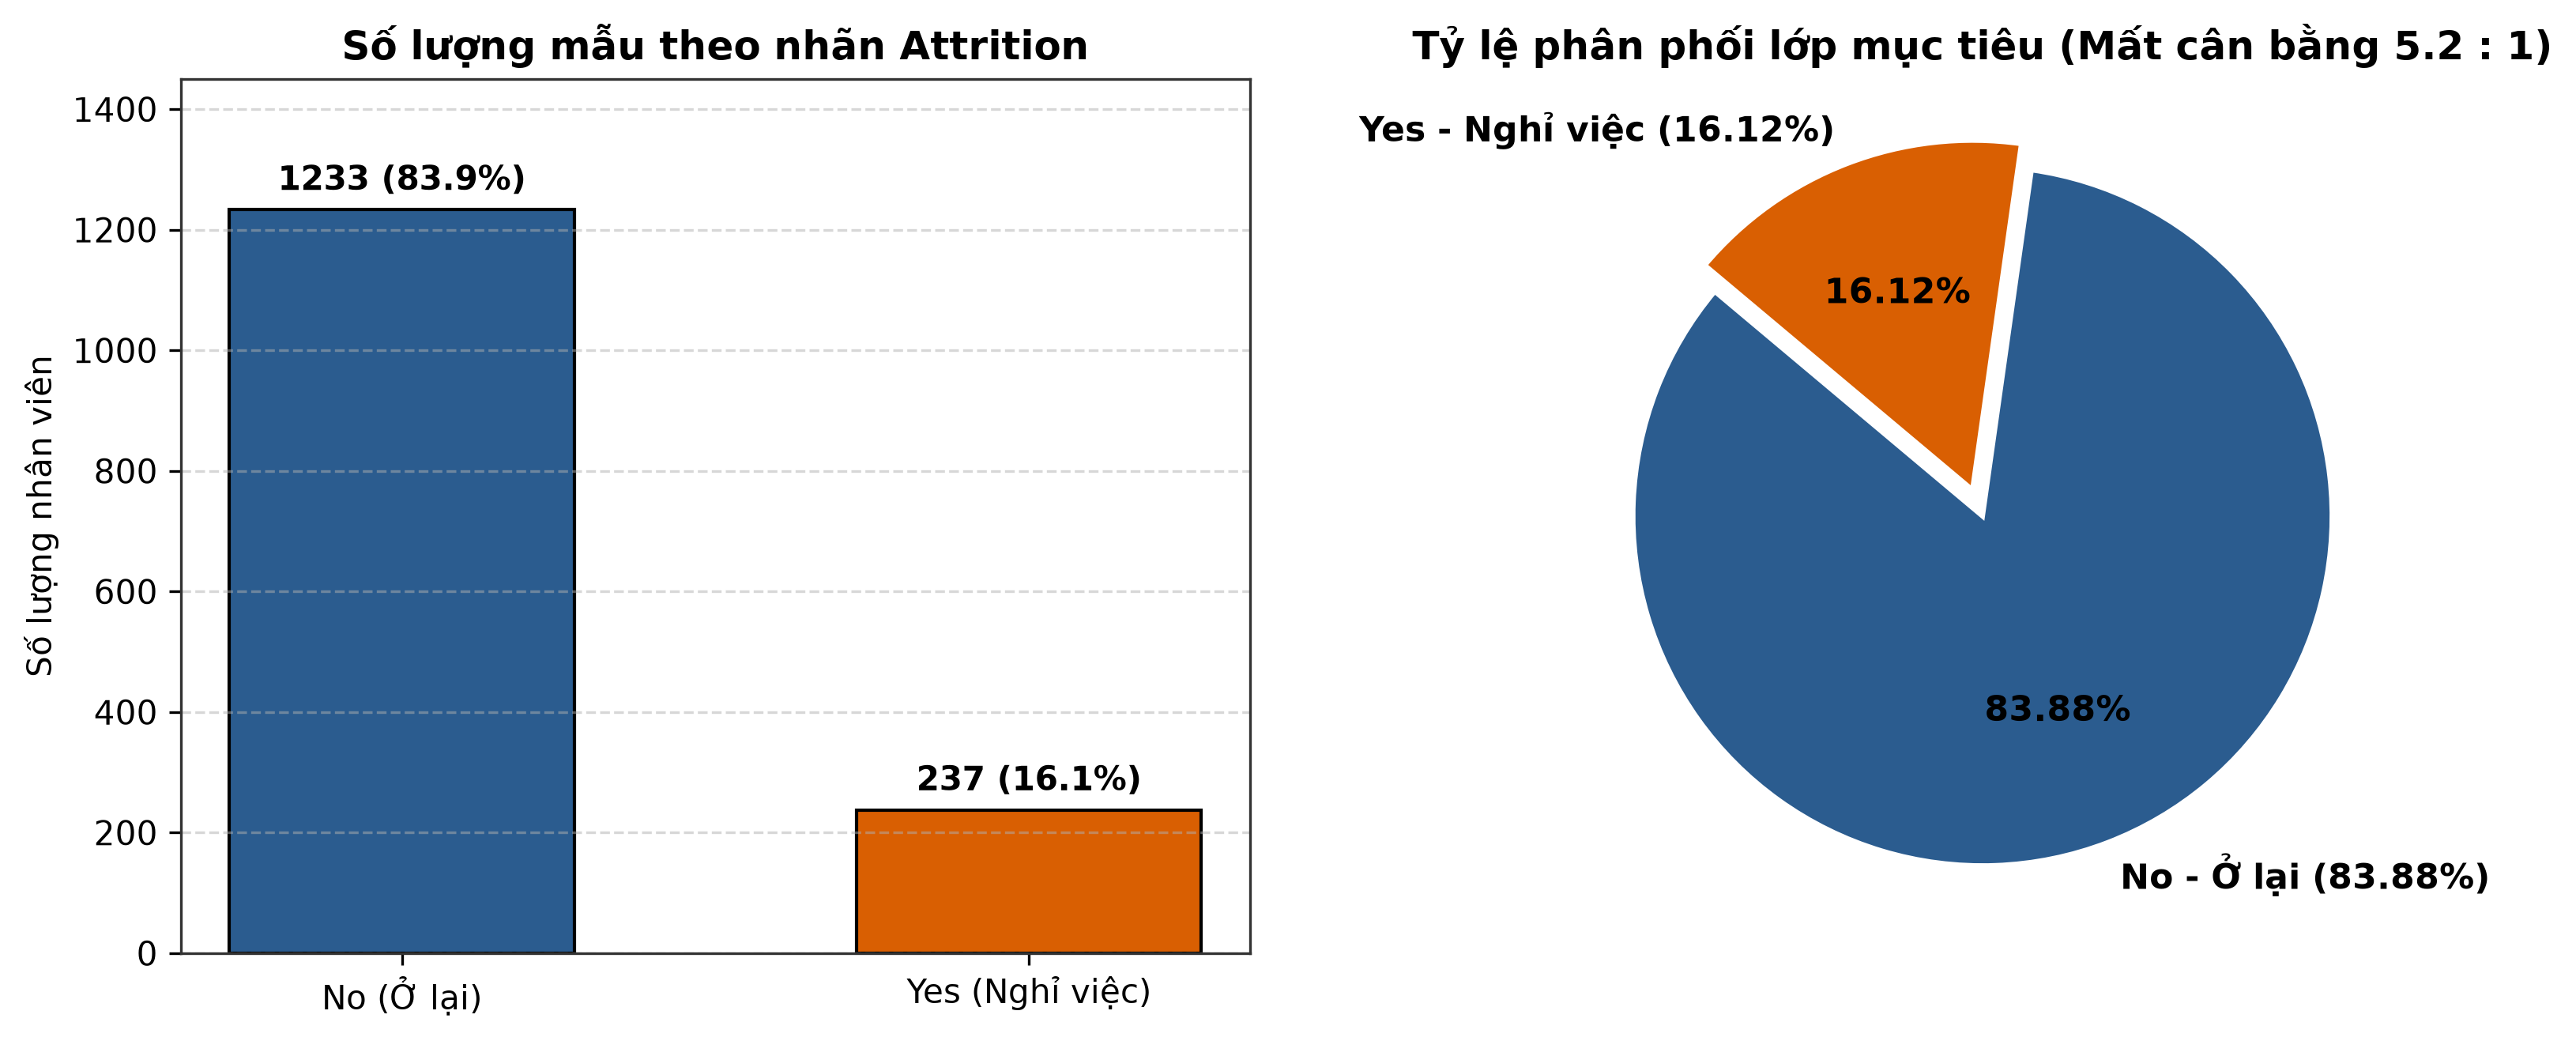

In [4]:
# 1.3. Phân tích phân phối nhãn mục tiêu Attrition
counts = df['Attrition'].value_counts()
pcts = df['Attrition'].value_counts(normalize=True) * 100
target_df = pd.DataFrame({'Số lượng nhân viên': counts, 'Tỷ lệ (%)': pcts.round(2)})
display(target_df)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
colors = ['#2b5c8f', '#d95f02']
bars = axes[0].bar(['No (Ở lại)', 'Yes (Nghỉ việc)'], counts.values, color=colors, width=0.55, edgecolor='black')
axes[0].set_title('Số lượng mẫu theo nhãn Attrition', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Số lượng nhân viên')
for bar in bars:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2., h + 20, f'{h} ({h/len(df)*100:.1f}%)', ha='center', fontweight='bold')
axes[0].set_ylim(0, 1450)
axes[1].pie(counts.values, labels=['No - Ở lại (83.88%)', 'Yes - Nghỉ việc (16.12%)'],
            colors=colors, autopct='%1.2f%%', startangle=140, explode=(0, 0.08))
axes[1].set_title('Tỷ lệ phân phối lớp mục tiêu (Mất cân bằng 5.2 : 1)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig1_target_distribution.png', dpi=300)
plt.show()

### 1.4. Phân tích 14 đặc trưng số: Ngoại lệ IQR, Kiểm định Mann-Whitney U & Phân phối

,Đặc trưng số,Mean (No),Mean (Yes),Median (No),Median (Yes),Skewness,IQR Outliers,Mann-Whitney p-val,Ý nghĩa TK (p<0.05)
0,Age,37.56,33.61,36.0,32.0,0.41,0 (0.0%),5.30e-11,Có (***)
1,MonthlyIncome,6832.74,4787.09,5204.0,3202.0,1.37,114 (7.8%),2.95e-14,Có (***)
2,DistanceFromHome,8.92,10.63,7.0,9.0,0.96,0 (0.0%),2.39e-03,Có (*)
3,TotalWorkingYears,11.86,8.24,10.0,7.0,1.12,63 (4.3%),2.40e-14,Có (***)
4,YearsAtCompany,7.37,5.13,6.0,3.0,1.76,104 (7.1%),2.92e-13,Có (***)
5,YearsInCurrentRole,4.48,2.90,3.0,2.0,0.92,21 (1.4%),4.43e-12,Có (***)
6,YearsSinceLastPromotion,2.23,1.95,1.0,1.0,1.98,107 (7.3%),4.12e-02,Có (*)
7,YearsWithCurrManager,4.37,2.85,3.0,2.0,0.83,14 (1.0%),1.81e-11,Có (***)
8,NumCompaniesWorked,2.65,2.94,2.0,1.0,1.03,52 (3.5%),2.42e-01,Không (Nhiễu)
9,PercentSalaryHike,15.23,15.10,14.0,14.0,0.82,0 (0.0%),3.66e-01,Không (Nhiễu)


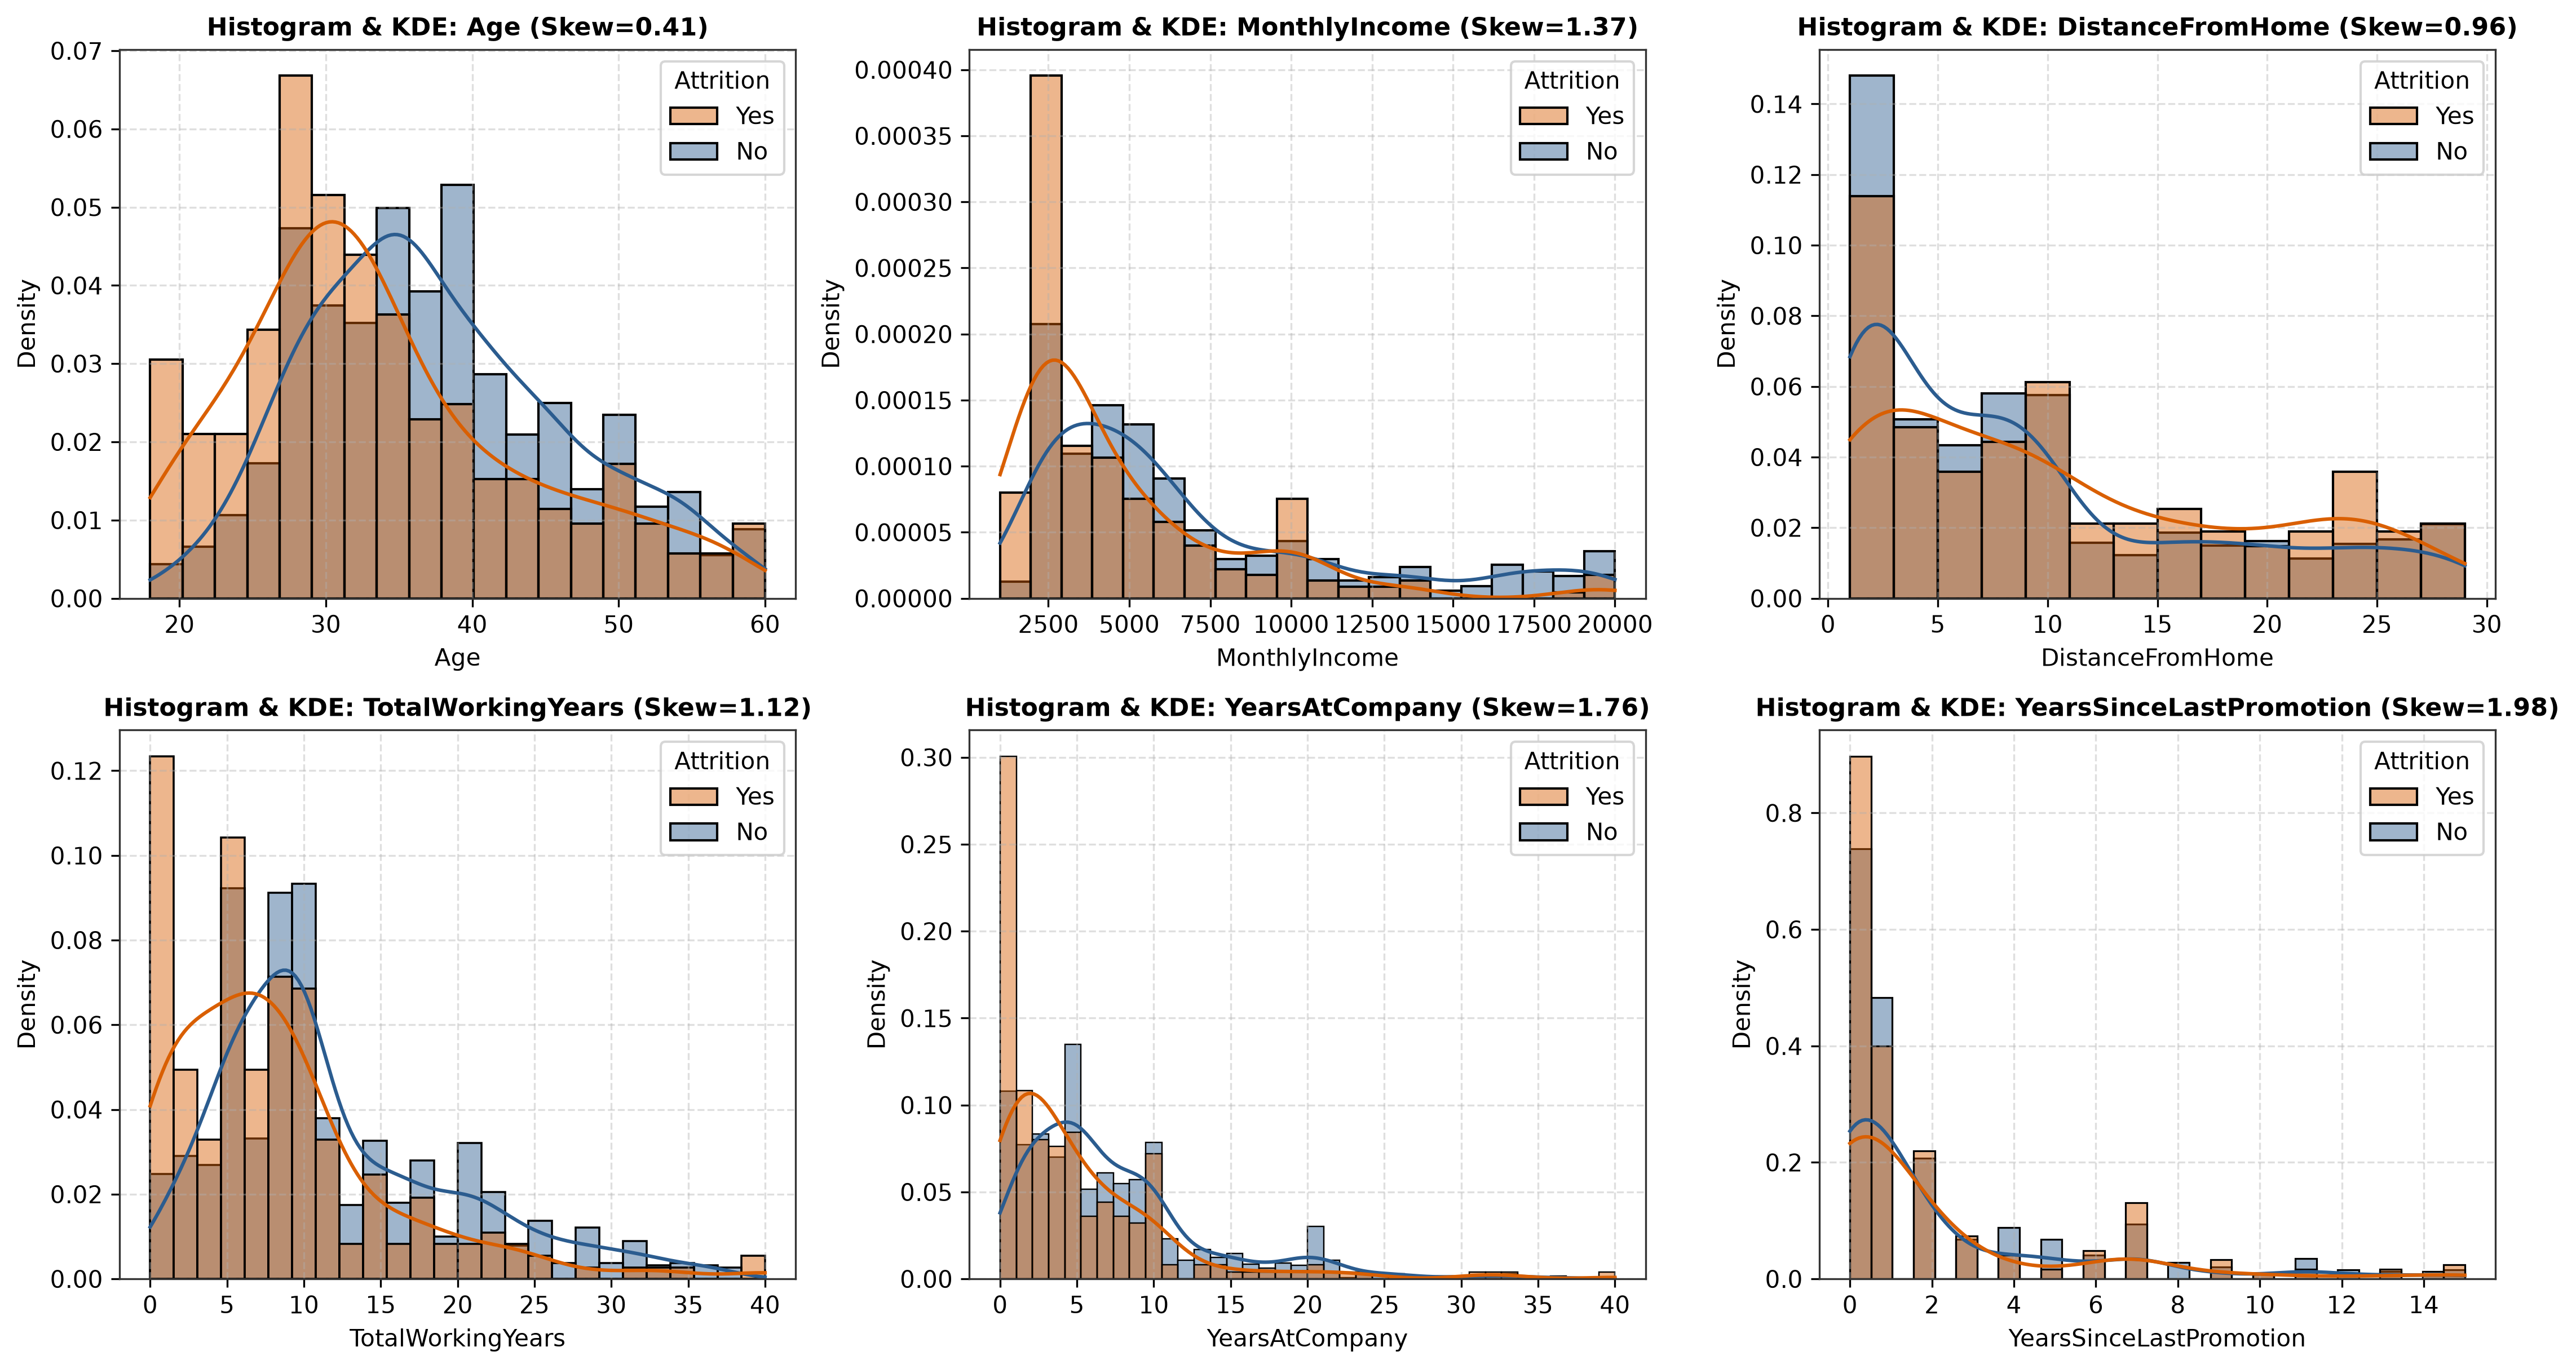

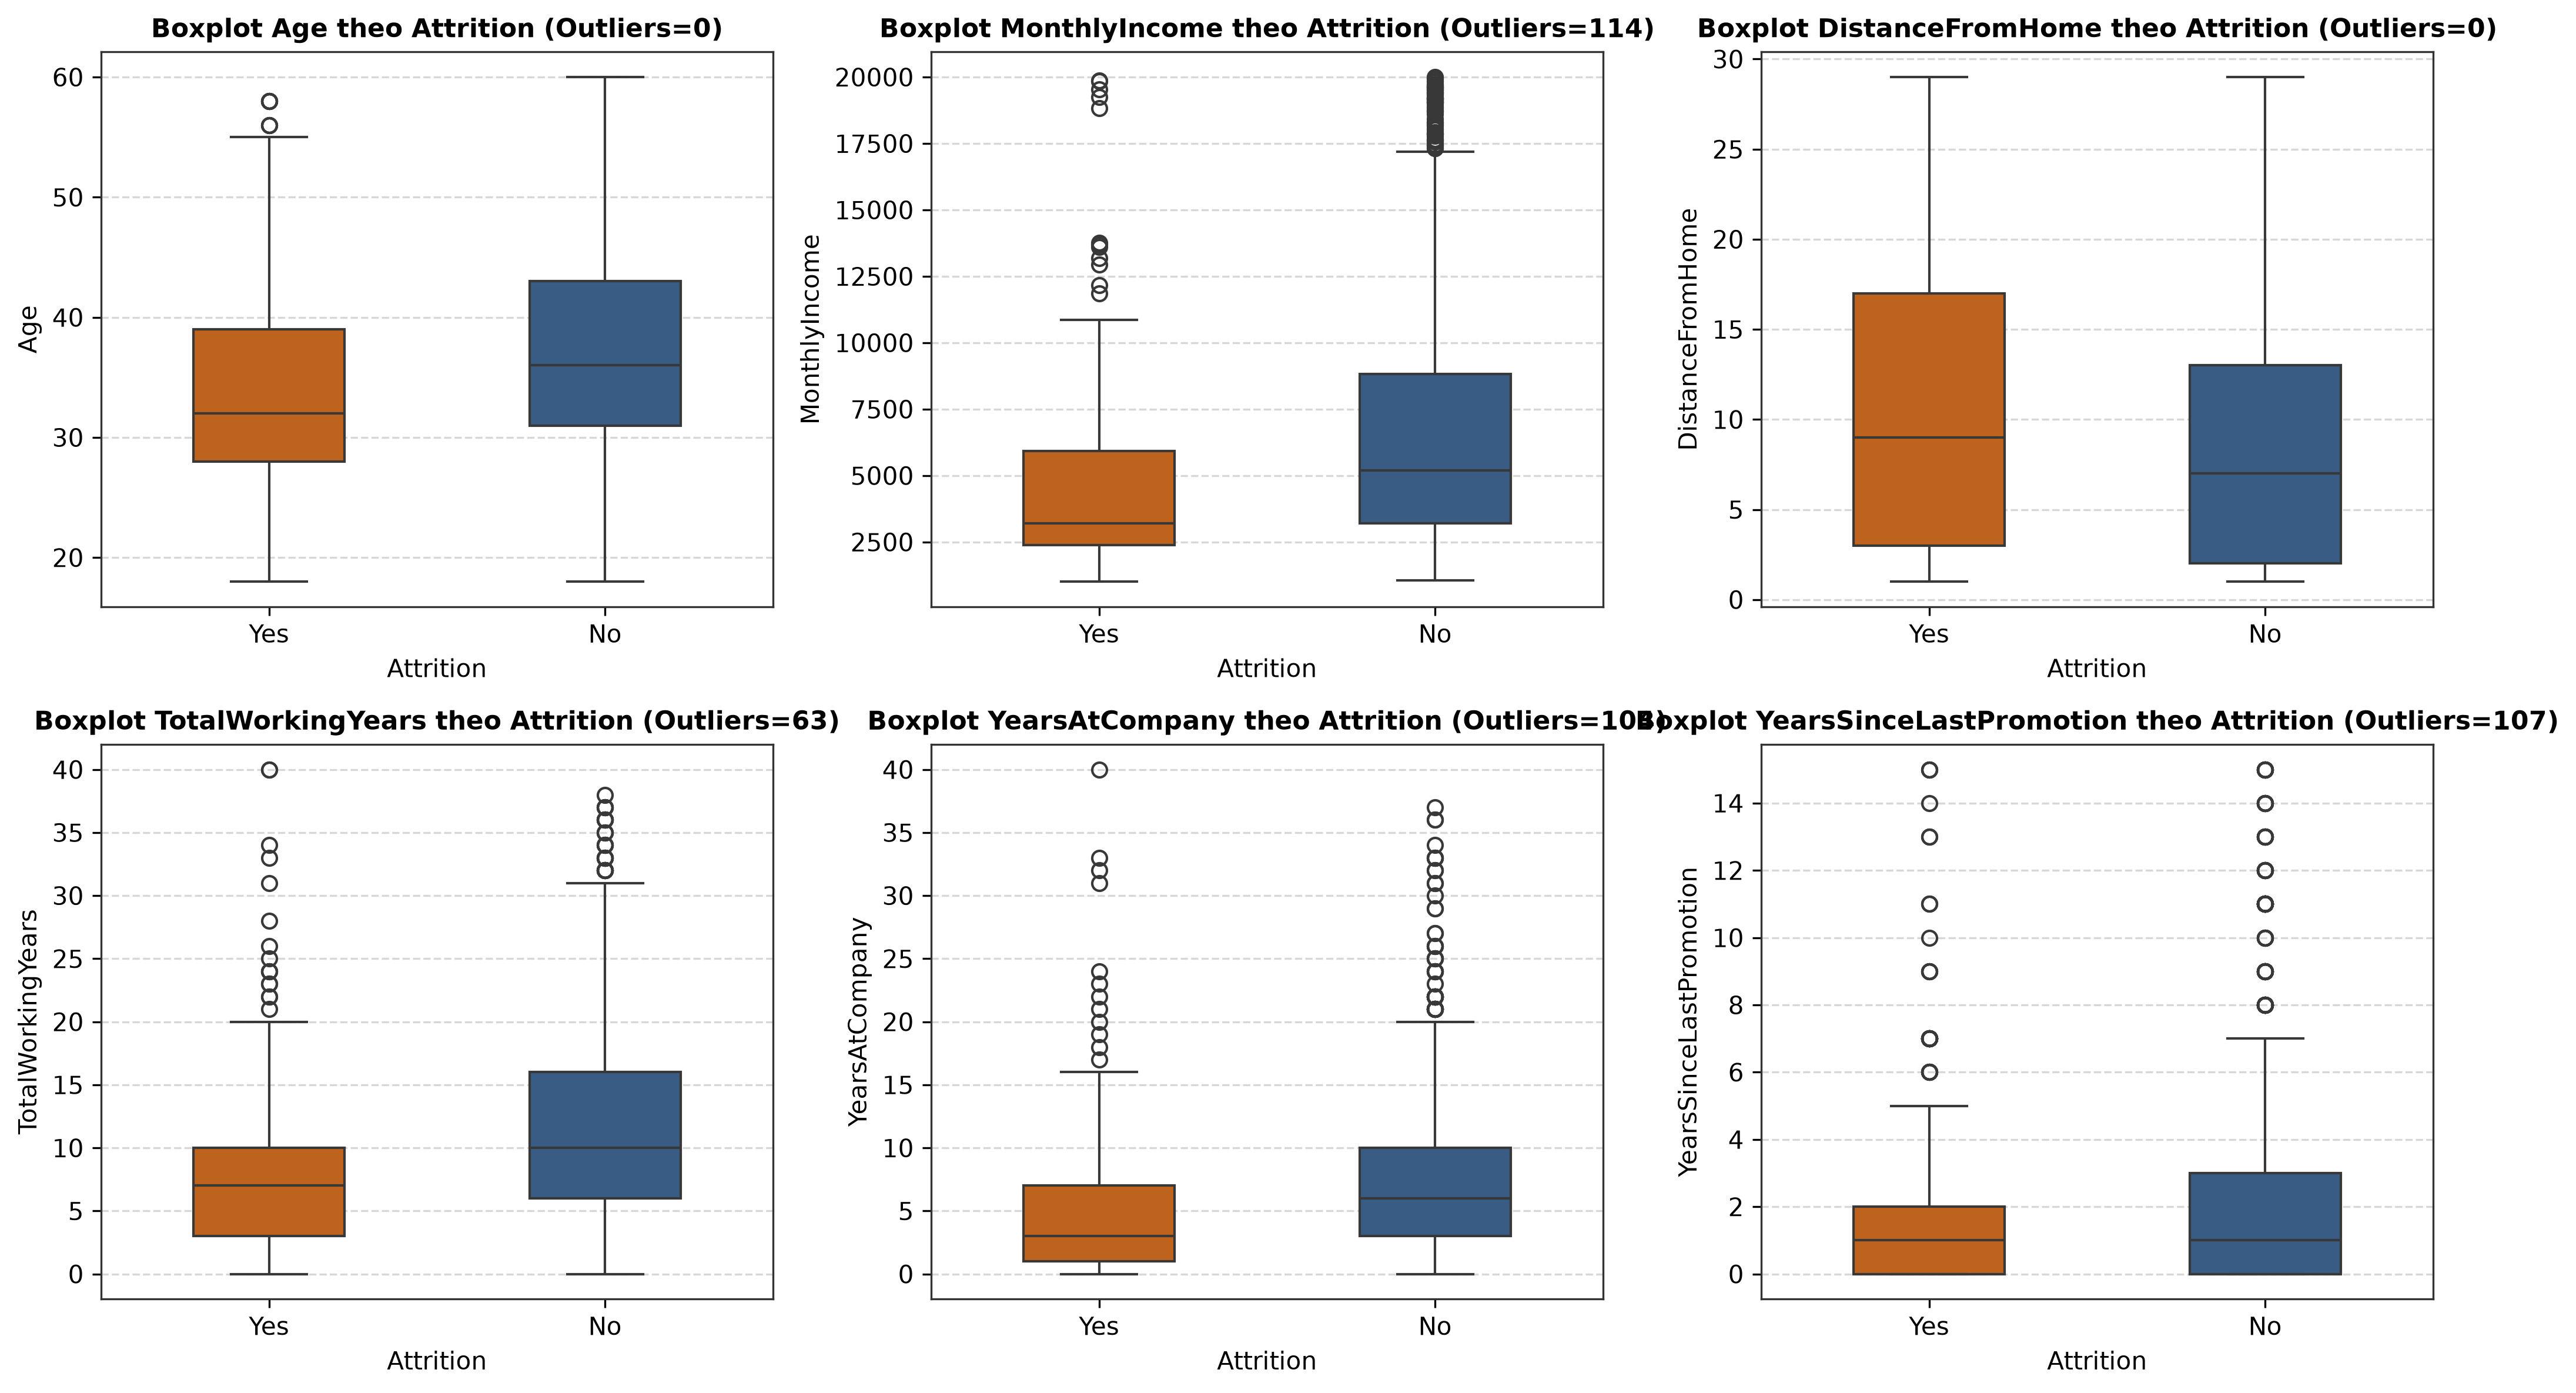

In [5]:
# 1.4. Thống kê mô tả, độ lệch (Skewness), ngoại lệ IQR và kiểm định Mann-Whitney U cho 14 biến số
continuous_cols = [
    'Age', 'MonthlyIncome', 'DistanceFromHome', 'TotalWorkingYears',
    'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
    'YearsWithCurrManager', 'NumCompaniesWorked', 'PercentSalaryHike',
    'TrainingTimesLastYear', 'DailyRate', 'HourlyRate', 'MonthlyRate'
]
stat_rows = []
for col in continuous_cols:
    g_no = df[df['Attrition'] == 'No'][col]
    g_yes = df[df['Attrition'] == 'Yes'][col]
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    n_out = int(((df[col] < (q1 - 1.5 * iqr)) | (df[col] > (q3 + 1.5 * iqr))).sum())
    u_stat, p_val = stats.mannwhitneyu(g_yes, g_no, alternative='two-sided')
    stat_rows.append({
        'Đặc trưng số': col,
        'Mean (No)': round(g_no.mean(), 2), 'Mean (Yes)': round(g_yes.mean(), 2),
        'Median (No)': round(g_no.median(), 2), 'Median (Yes)': round(g_yes.median(), 2),
        'Skewness': round(df[col].skew(), 2),
        'IQR Outliers': f"{n_out} ({n_out/len(df)*100:.1f}%)",
        'Mann-Whitney p-val': f"{p_val:.2e}",
        'Ý nghĩa TK (p<0.05)': 'Có (***)' if p_val < 0.001 else ('Có (*)' if p_val < 0.05 else 'Không (Nhiễu)')
    })
stat_num_df = pd.DataFrame(stat_rows)
display(stat_num_df)

# Vẽ Histogram + KDE và Boxplot cho 6 đặc trưng số có ý nghĩa thống kê mạnh nhất
num_focus = ['Age', 'MonthlyIncome', 'DistanceFromHome', 'TotalWorkingYears', 'YearsAtCompany', 'YearsSinceLastPromotion']

fig, axes = plt.subplots(2, 3, figsize=(15, 8.2))
axes = axes.flatten()
for i, col in enumerate(num_focus):
    sns.histplot(data=df, x=col, hue='Attrition', kde=True, stat='density', common_norm=False,
                 palette={'No': '#2b5c8f', 'Yes': '#d95f02'}, alpha=0.45, ax=axes[i])
    axes[i].set_title(f'Histogram & KDE: {col} (Skew={df[col].skew():.2f})', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig10_numeric_histograms.png', dpi=300)
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()
for i, col in enumerate(num_focus):
    sns.boxplot(data=df, x='Attrition', y=col, ax=axes[i], palette={'No': '#2b5c8f', 'Yes': '#d95f02'}, width=0.45)
    axes[i].set_title(f'Boxplot {col} theo Attrition', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig2_numeric_distributions.png', dpi=300)
plt.show()

### 1.5. Phân tích 15 đặc trưng phân loại & thứ bậc: Kiểm định Chi-Square ($\chi^2$) và Biểu đồ tỷ lệ nghỉ việc

,Đặc trưng,Số nhóm,Chi2 Stat,p-value,Nhóm nghỉ cao nhất,Nhóm nghỉ thấp nhất,Kết luận (p<0.05)
0,OverTime,2,87.56,8.16e-21,Yes (30.5%),No (10.4%),Ảnh hưởng mạnh
1,JobRole,9,86.19,2.75e-15,Sales Representative (39.8%),Research Director (2.5%),Ảnh hưởng mạnh
2,JobLevel,5,72.53,6.63e-15,1 (26.3%),4 (4.7%),Ảnh hưởng mạnh
3,StockOptionLevel,4,60.60,4.38e-13,0 (24.4%),2 (7.6%),Ảnh hưởng mạnh
4,MaritalStatus,3,46.16,9.46e-11,Single (25.5%),Divorced (10.1%),Ảnh hưởng mạnh
5,JobInvolvement,4,28.49,2.86e-06,1 (33.7%),4 (9.0%),Ảnh hưởng mạnh
6,BusinessTravel,3,24.18,5.61e-06,Travel_Frequently (24.9%),Non-Travel (8.0%),Ảnh hưởng mạnh
7,EnvironmentSatisfaction,4,22.50,5.12e-05,1 (25.4%),4 (13.5%),Ảnh hưởng mạnh
8,JobSatisfaction,4,17.51,5.56e-04,1 (22.8%),4 (11.3%),Ảnh hưởng mạnh
9,WorkLifeBalance,4,16.33,9.73e-04,1 (31.2%),3 (14.2%),Ảnh hưởng mạnh


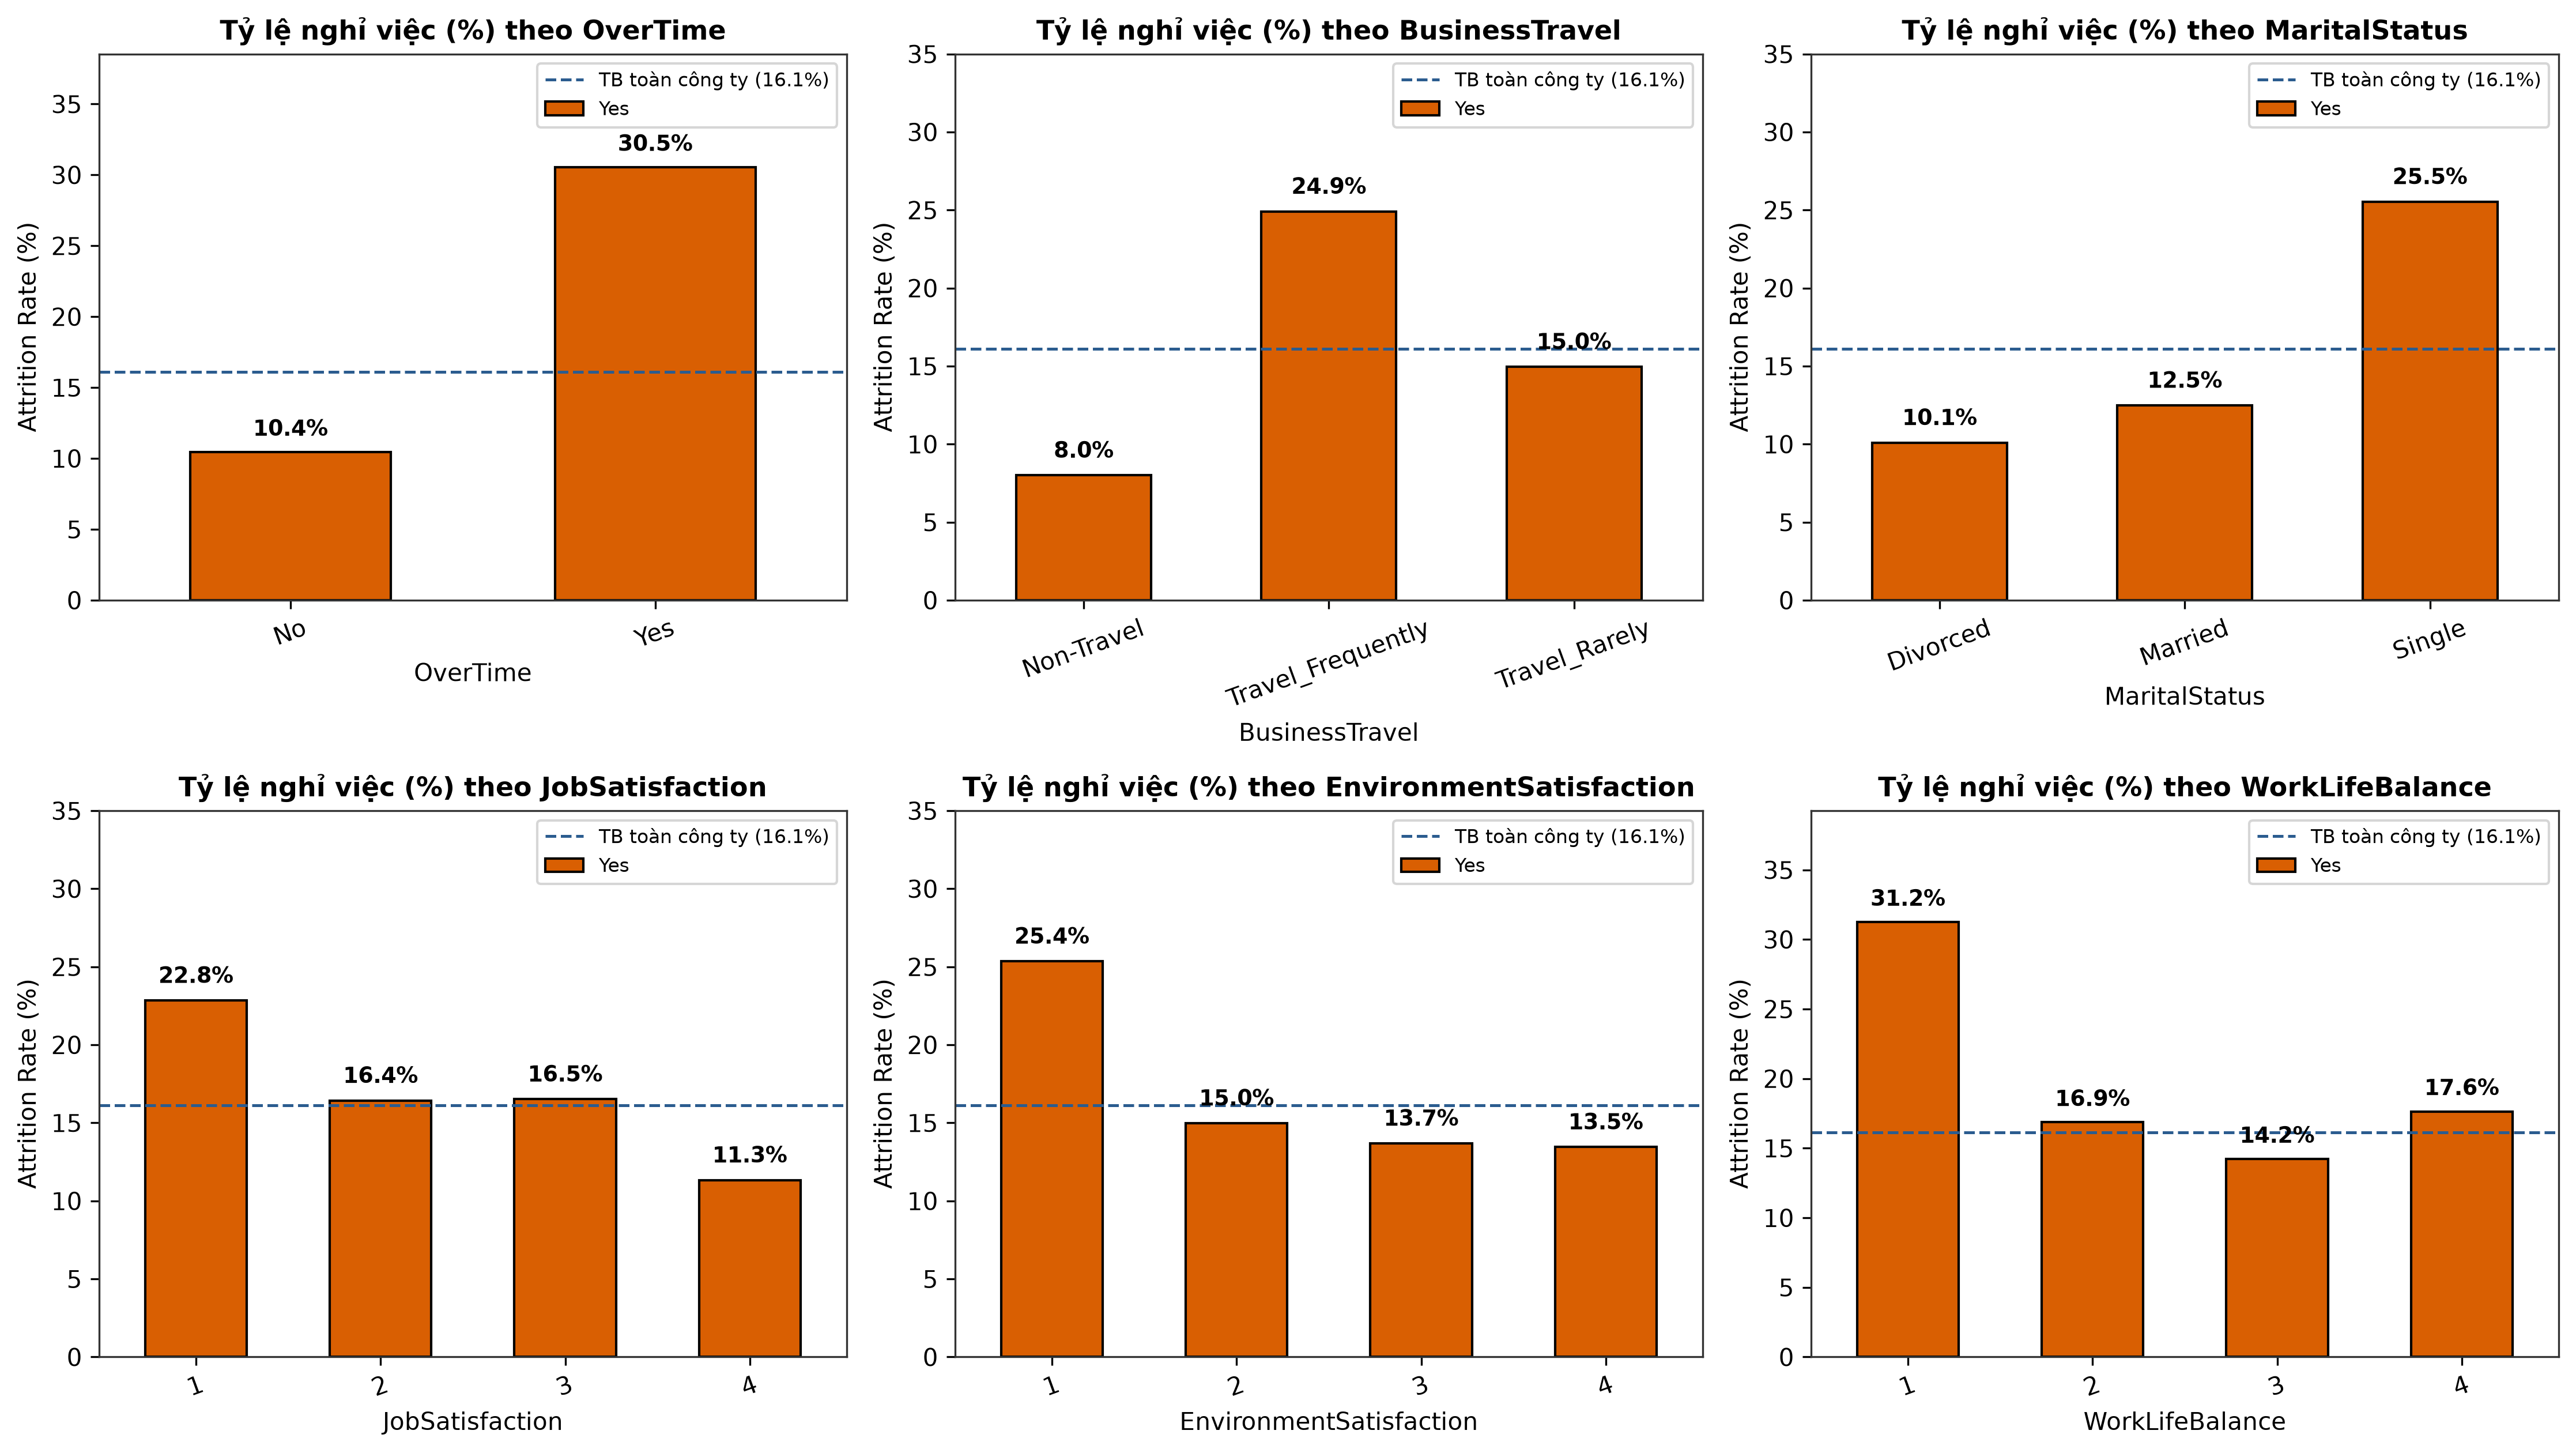

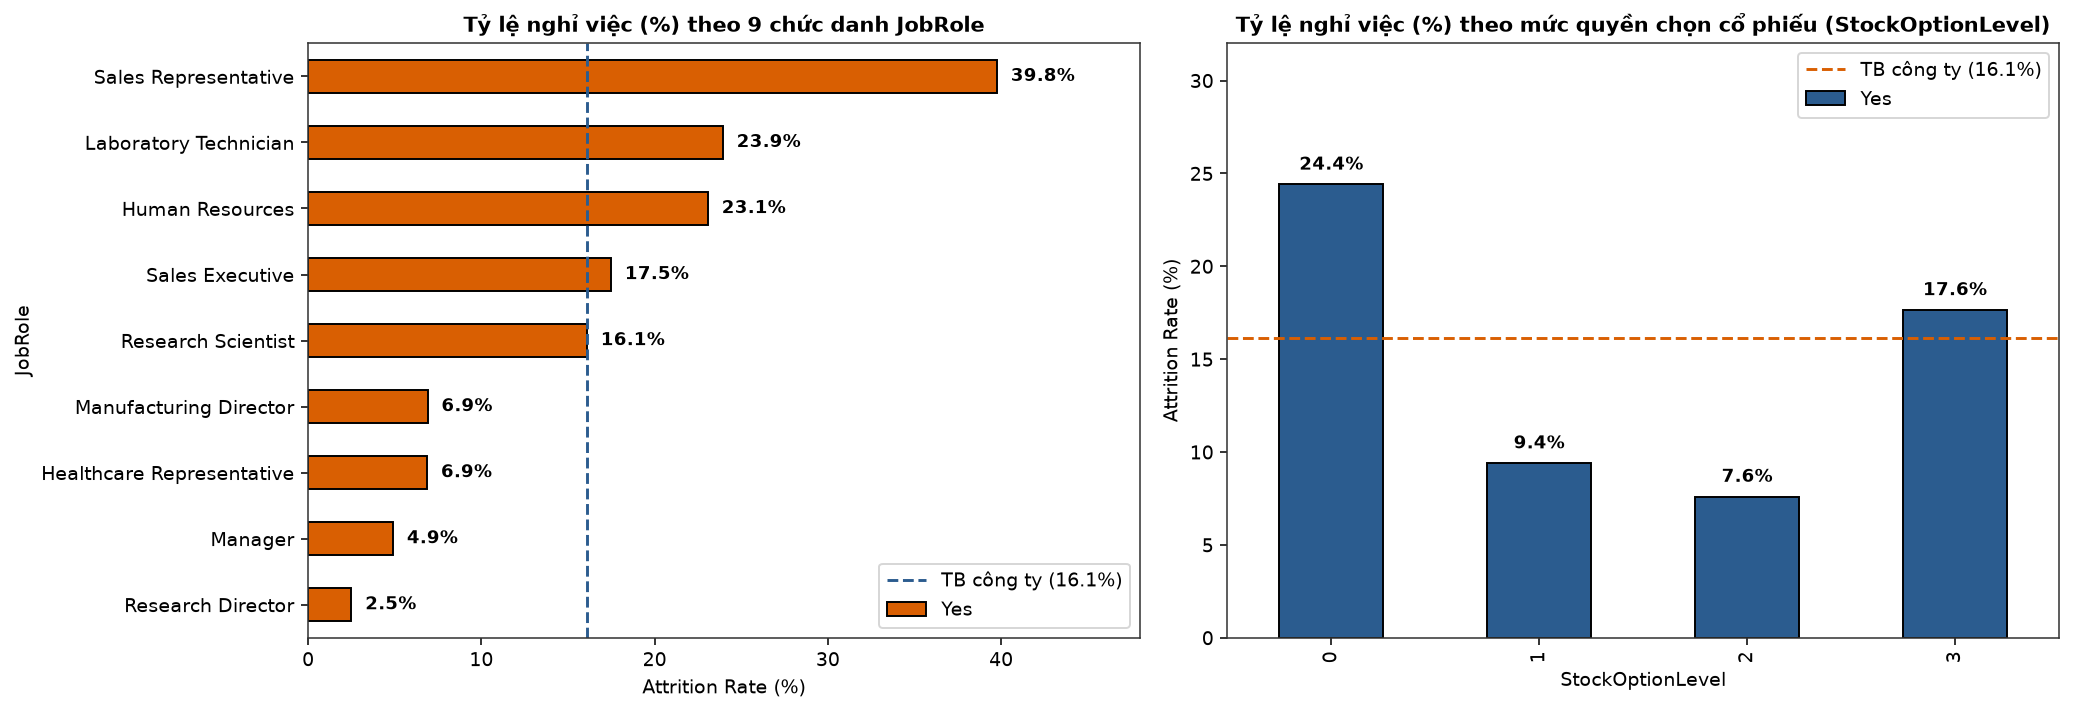

In [6]:
# 1.5. Kiểm định Chi-Square (Chi2) xếp hạng mức độ phụ thuộc của 15 biến phân loại/thứ bậc vào Attrition
cat_ord_cols = [
    'OverTime', 'BusinessTravel', 'JobRole', 'MaritalStatus', 'Department',
    'EducationField', 'Gender', 'StockOptionLevel', 'JobLevel',
    'JobSatisfaction', 'EnvironmentSatisfaction', 'WorkLifeBalance',
    'JobInvolvement', 'Education', 'PerformanceRating'
]
chi2_rows = []
for col in cat_ord_cols:
    ct = pd.crosstab(df[col], df['Attrition'])
    chi2, p_val, dof, _ = stats.chi2_contingency(ct)
    rates = (pd.crosstab(df[col], df['Attrition'], normalize='index')['Yes'] * 100).round(1)
    chi2_rows.append({
        'Đặc trưng': col, 'Số nhóm': df[col].nunique(),
        'Chi2 Stat': round(chi2, 2), 'p-value': f"{p_val:.2e}",
        'Nhóm nghỉ cao nhất': f"{rates.idxmax()} ({rates.max()}%)",
        'Nhóm nghỉ thấp nhất': f"{rates.idxmin()} ({rates.min()}%)",
        'Kết luận (p<0.05)': 'Ảnh hưởng mạnh' if p_val < 0.001 else ('Có ảnh hưởng' if p_val < 0.05 else 'Không ảnh hưởng')
    })
chi2_df = pd.DataFrame(chi2_rows).sort_values(by='Chi2 Stat', ascending=False).reset_index(drop=True)
display(chi2_df)

# Biểu đồ tỷ lệ nghỉ việc theo 6 biến phân loại/thứ bậc chính
cat_focus = ['OverTime', 'BusinessTravel', 'MaritalStatus', 'Department', 'JobSatisfaction', 'EnvironmentSatisfaction']
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
axes = axes.flatten()
for i, col in enumerate(cat_focus):
    ct_norm = pd.crosstab(df[col], df['Attrition'], normalize='index')['Yes'] * 100
    ct_norm.plot(kind='bar', ax=axes[i], color='#d95f02', edgecolor='black', width=0.55)
    axes[i].axhline(16.12, color='#2b5c8f', linestyle='--', label='TB công ty (16.1%)')
    axes[i].set_title(f'Tỷ lệ nghỉ việc (%) theo {col}', fontweight='bold')
    axes[i].set_ylabel('Attrition Rate (%)')
    axes[i].legend()
plt.tight_layout()
plt.show()

# Biểu đồ tỷ lệ nghỉ việc theo 9 chức danh JobRole và mức quyền chọn cổ phiếu StockOptionLevel
fig_job, axes = plt.subplots(1, 2, figsize=(14, 4.8))
jr_ct = pd.crosstab(df['JobRole'], df['Attrition'], normalize='index')['Yes'].sort_values(ascending=True) * 100
jr_ct.plot(kind='barh', ax=axes[0], color='#d95f02', edgecolor='black')
axes[0].axvline(16.12, color='#2b5c8f', linestyle='--', label='TB công ty (16.1%)')
axes[0].set_title('Tỷ lệ nghỉ việc (%) theo 9 Chức danh (JobRole)', fontweight='bold')
st_ct = pd.crosstab(df['StockOptionLevel'], df['Attrition'], normalize='index')['Yes'] * 100
st_ct.plot(kind='bar', ax=axes[1], color='#2b5c8f', edgecolor='black')
axes[1].axhline(16.12, color='#d95f02', linestyle='--', label='TB công ty (16.1%)')
axes[1].set_title('Tỷ lệ nghỉ việc (%) theo Quyền chọn cổ phiếu (StockOptionLevel)', fontweight='bold')
plt.tight_layout()
plt.show()

---
### 1.6. Ma trận tương quan Pearson, Đa cộng tuyến và Kiểm tra rò rỉ dữ liệu (Data Leakage)

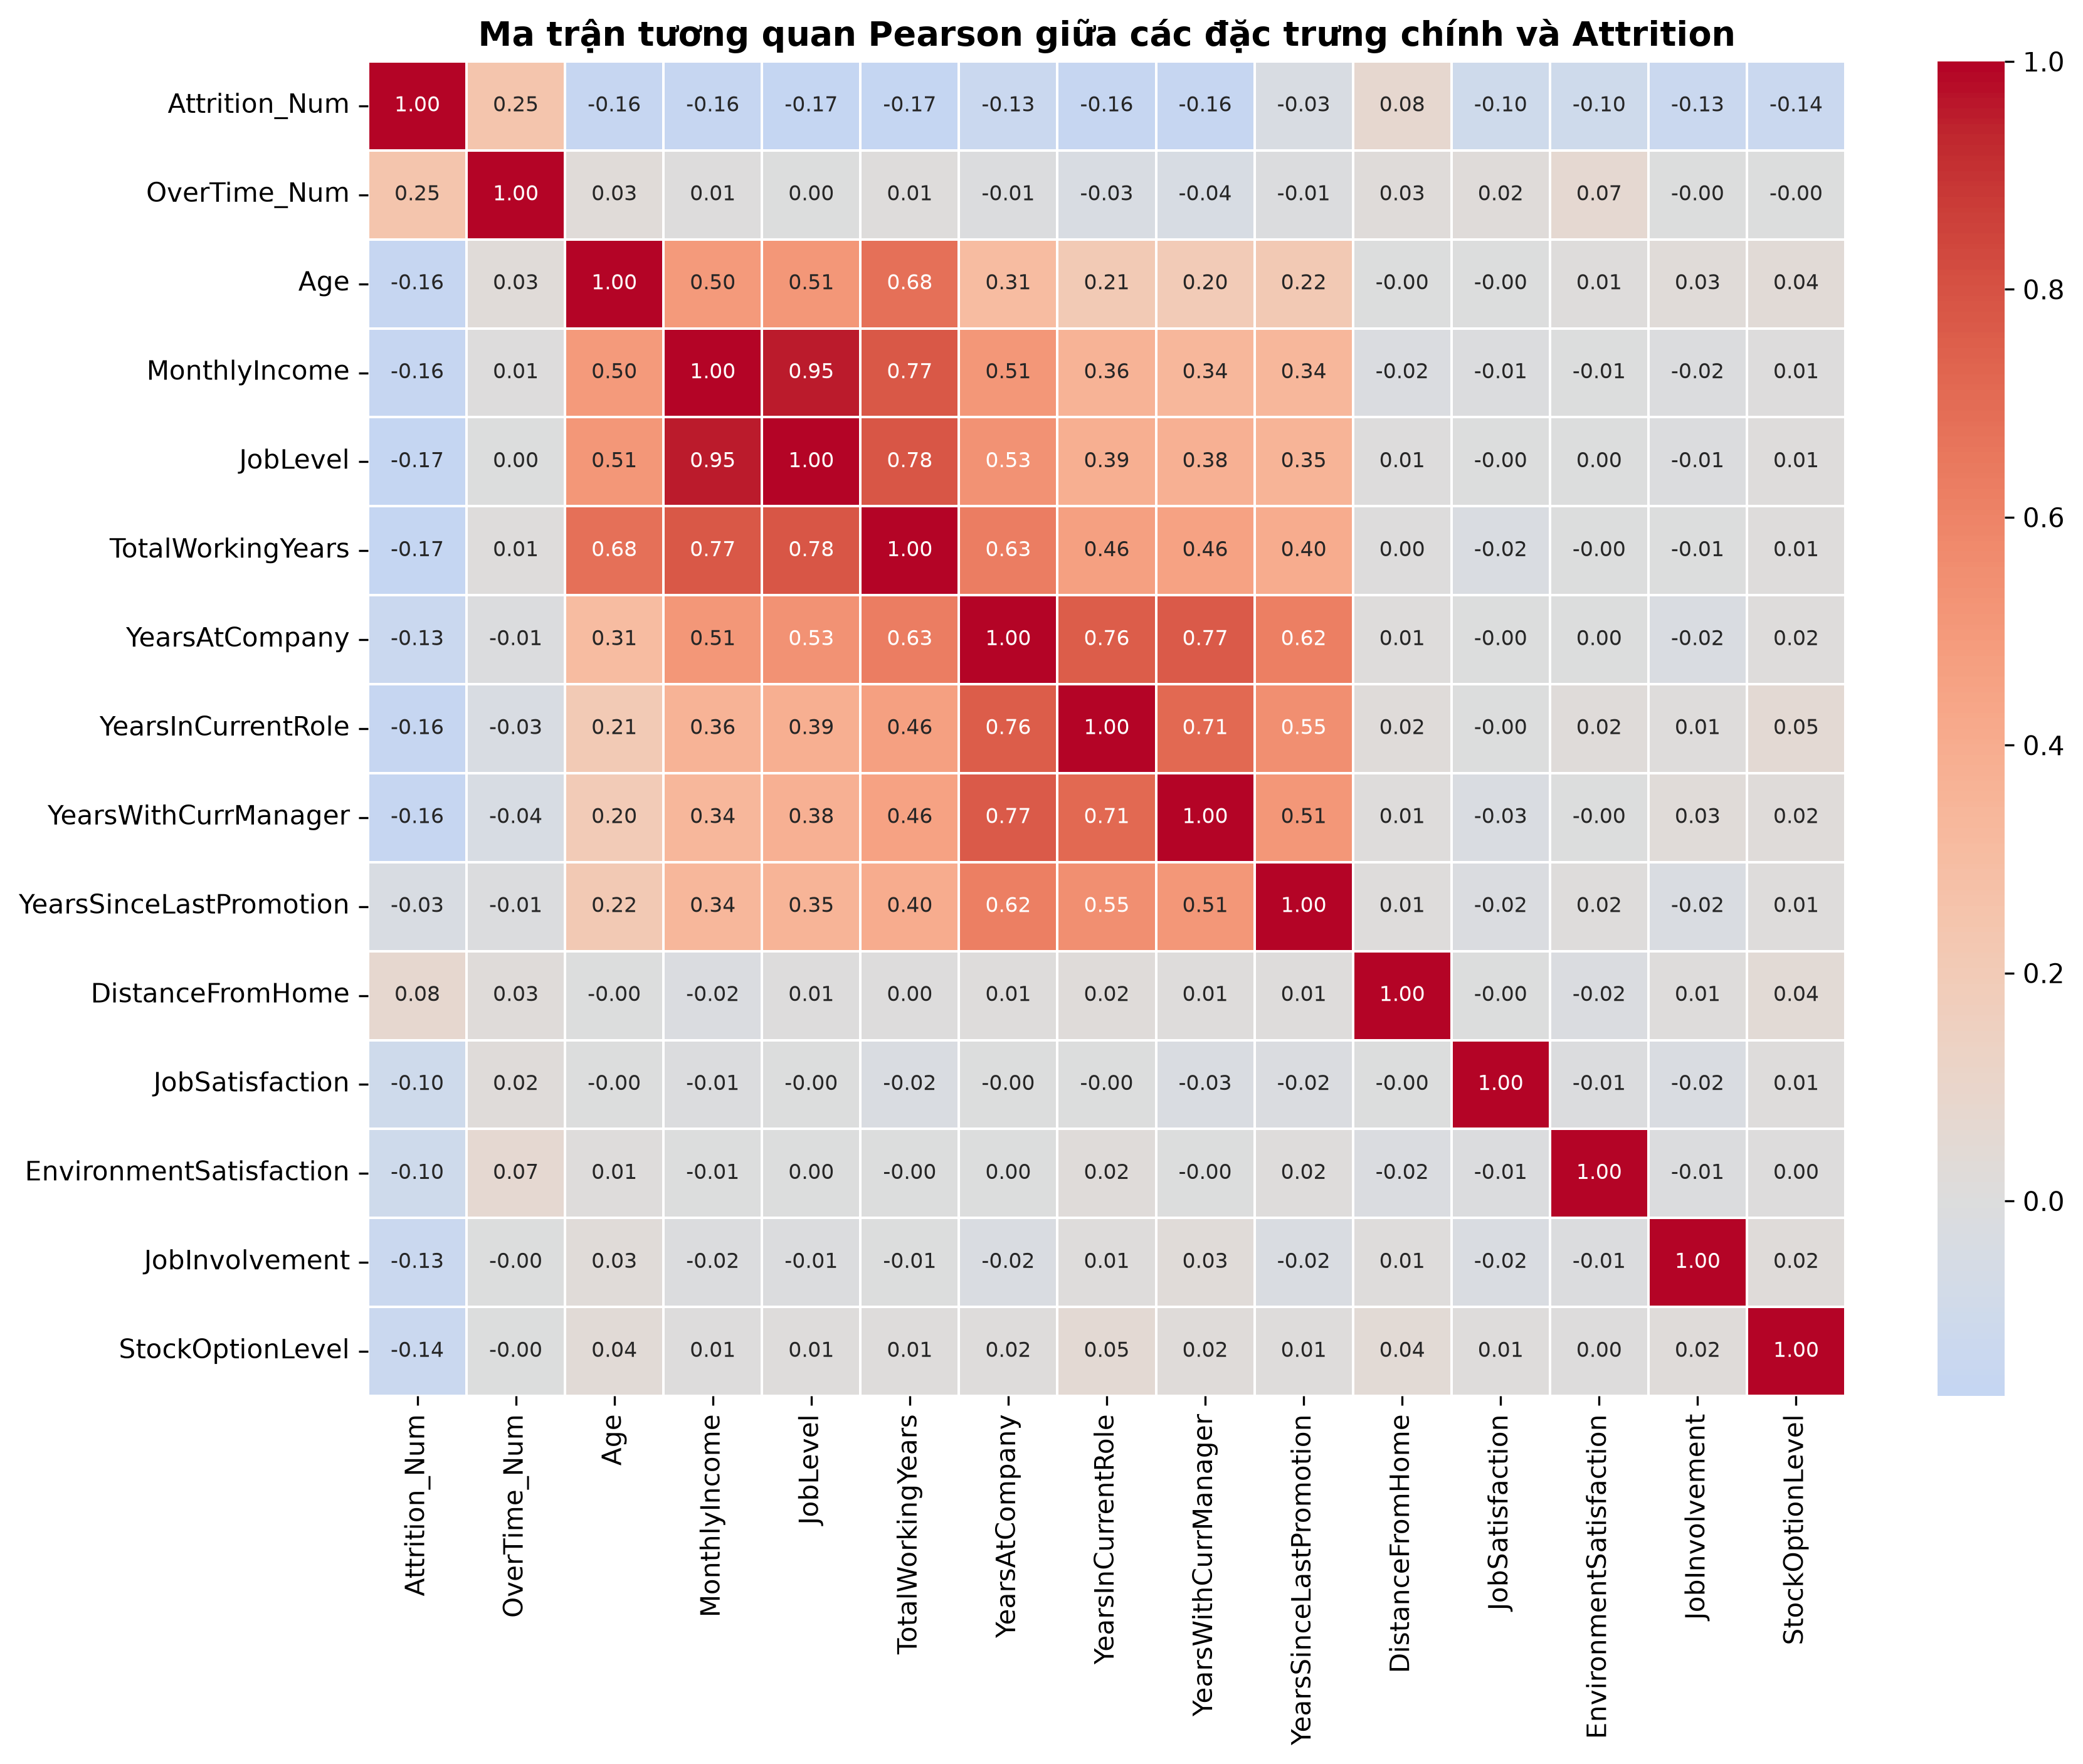

In [7]:
# 1.6. Ma trận tương quan Pearson và phát hiện các cặp biến đa cộng tuyến cao (|r| >= 0.65)
df_corr = df.copy()
df_corr['Attrition_Num'] = (df_corr['Attrition'] == 'Yes').astype(int)
df_corr['OverTime_Num'] = (df_corr['OverTime'] == 'Yes').astype(int)
corr_cols = [
    'Attrition_Num', 'OverTime_Num', 'Age', 'MonthlyIncome', 'JobLevel',
    'TotalWorkingYears', 'YearsAtCompany', 'YearsInCurrentRole',
    'YearsWithCurrManager', 'YearsSinceLastPromotion', 'DistanceFromHome',
    'JobSatisfaction', 'EnvironmentSatisfaction', 'JobInvolvement', 'StockOptionLevel'
]
corr_matrix = df_corr[corr_cols].corr()

plt.figure(figsize=(12, 9.5))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Ma trận tương quan Pearson giữa các đặc trưng chính và Attrition', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig4_correlation_heatmap.png', dpi=300)
plt.show()

---
## Phần 2: Chia Tập Dữ Liệu và Thiết Kế 2 Luồng Tiền Xử Lý / Kỹ Thuật Đặc Trưng
### 2.1. Chia tập dữ liệu Train / Test (80% / 20%) phân tầng (`stratify=y`)

In [8]:
# 2.1. Chia dữ liệu Train (80%) và Test (20%) theo phương pháp phân tầng
X = df.drop(columns=['Attrition'])
y = (df['Attrition'] == 'Yes').astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
split_summary = pd.DataFrame({
    'Tập dữ liệu': ['Tập huấn luyện (Train - 80%)', 'Tập kiểm thử (Test - 20%)', 'Tổng cộng (100%)'],
    'Tổng số mẫu': [len(X_train), len(X_test), len(X)],
    'Số mẫu Ở lại (No=0)': [int((y_train == 0).sum()), int((y_test == 0).sum()), int((y == 0).sum())],
    'Số mẫu Nghỉ việc (Yes=1)': [int((y_train == 1).sum()), int((y_test == 1).sum()), int((y == 1).sum())],
    'Tỷ lệ lớp Yes (%)': [round(y_train.mean()*100, 2), round(y_test.mean()*100, 2), round(y.mean()*100, 2)]
})
display(split_summary)

,Tập dữ liệu,Tổng số mẫu,Số mẫu Ở lại (No=0),Số mẫu Nghỉ việc (Yes=1),Tỷ lệ lớp Yes (%)
0,Tập huấn luyện (Train - 80%),1176,986,190,16.16
1,Tập kiểm thử (Test - 20%),294,247,47,15.99
2,Tổng cộng (100%),1470,1233,237,16.12


### 2.2. Xây dựng Luồng A (Pipeline Cơ bản) và Luồng B (Pipeline Cải tiến)
- **Luồng A (`preprocessor_A`):** `SimpleImputer` + `StandardScaler` + `OneHotEncoder(drop='first')` (44 chiều).
- **Luồng B (`preprocessor_B`):** `HRFeatureEngineer` (tạo 7 đặc trưng HR mới, mã hóa thứ bậc `BusinessTravel_Ord`, biến đổi `log1p`, loại bỏ cột đa cộng tuyến/nhiễu) + `RobustScaler` (46 chiều).

1. Bảng so sánh hệ số bất đối xứng (Skewness) trước và sau biến đổi log1p ở Luồng B:


,Đặc trưng lệch phải,Skewness Gốc (Luồng A),Skewness Sau log1p (Luồng B)
0,MonthlyIncome,1.333,0.252
1,TotalWorkingYears,1.104,-0.634
2,YearsAtCompany,1.733,-0.226
3,YearsSinceLastPromotion,1.971,0.720
4,DistanceFromHome,0.928,-0.060


2. Top 15 đặc trưng có điểm ANOVA F-Score cao nhất trong Luồng B (nhiều đặc trưng HR mới đứng đầu):


,Đặc trưng (Luồng B),Loại đặc trưng,ANOVA F-Score,p-value
0,TotalWorkingYears,Đặc trưng Gốc / One-Hot,81.66,6.49e-19
1,YoungSingleLowIncome,Đặc trưng HR Mới (Engineered),64.26,2.62e-15
2,YearsAtCompany,Đặc trưng Gốc / One-Hot,58.33,4.57e-14
3,OverTime_Yes,Đặc trưng Gốc / One-Hot,56.56,1.08e-13
4,MonthlyIncome,Đặc trưng Gốc / One-Hot,50.87,1.72e-12
5,Age,Đặc trưng Gốc / One-Hot,41.73,1.53e-10
6,MaritalStatus_Single,Đặc trưng Gốc / One-Hot,35.98,2.65e-09
7,YearsWithCurrManager,Đặc trưng Gốc / One-Hot,34.43,5.75e-09
8,OverallSatisfaction,Đặc trưng HR Mới (Engineered),34.04,6.99e-09
9,YearsInCurrentRole,Đặc trưng Gốc / One-Hot,33.69,8.30e-09


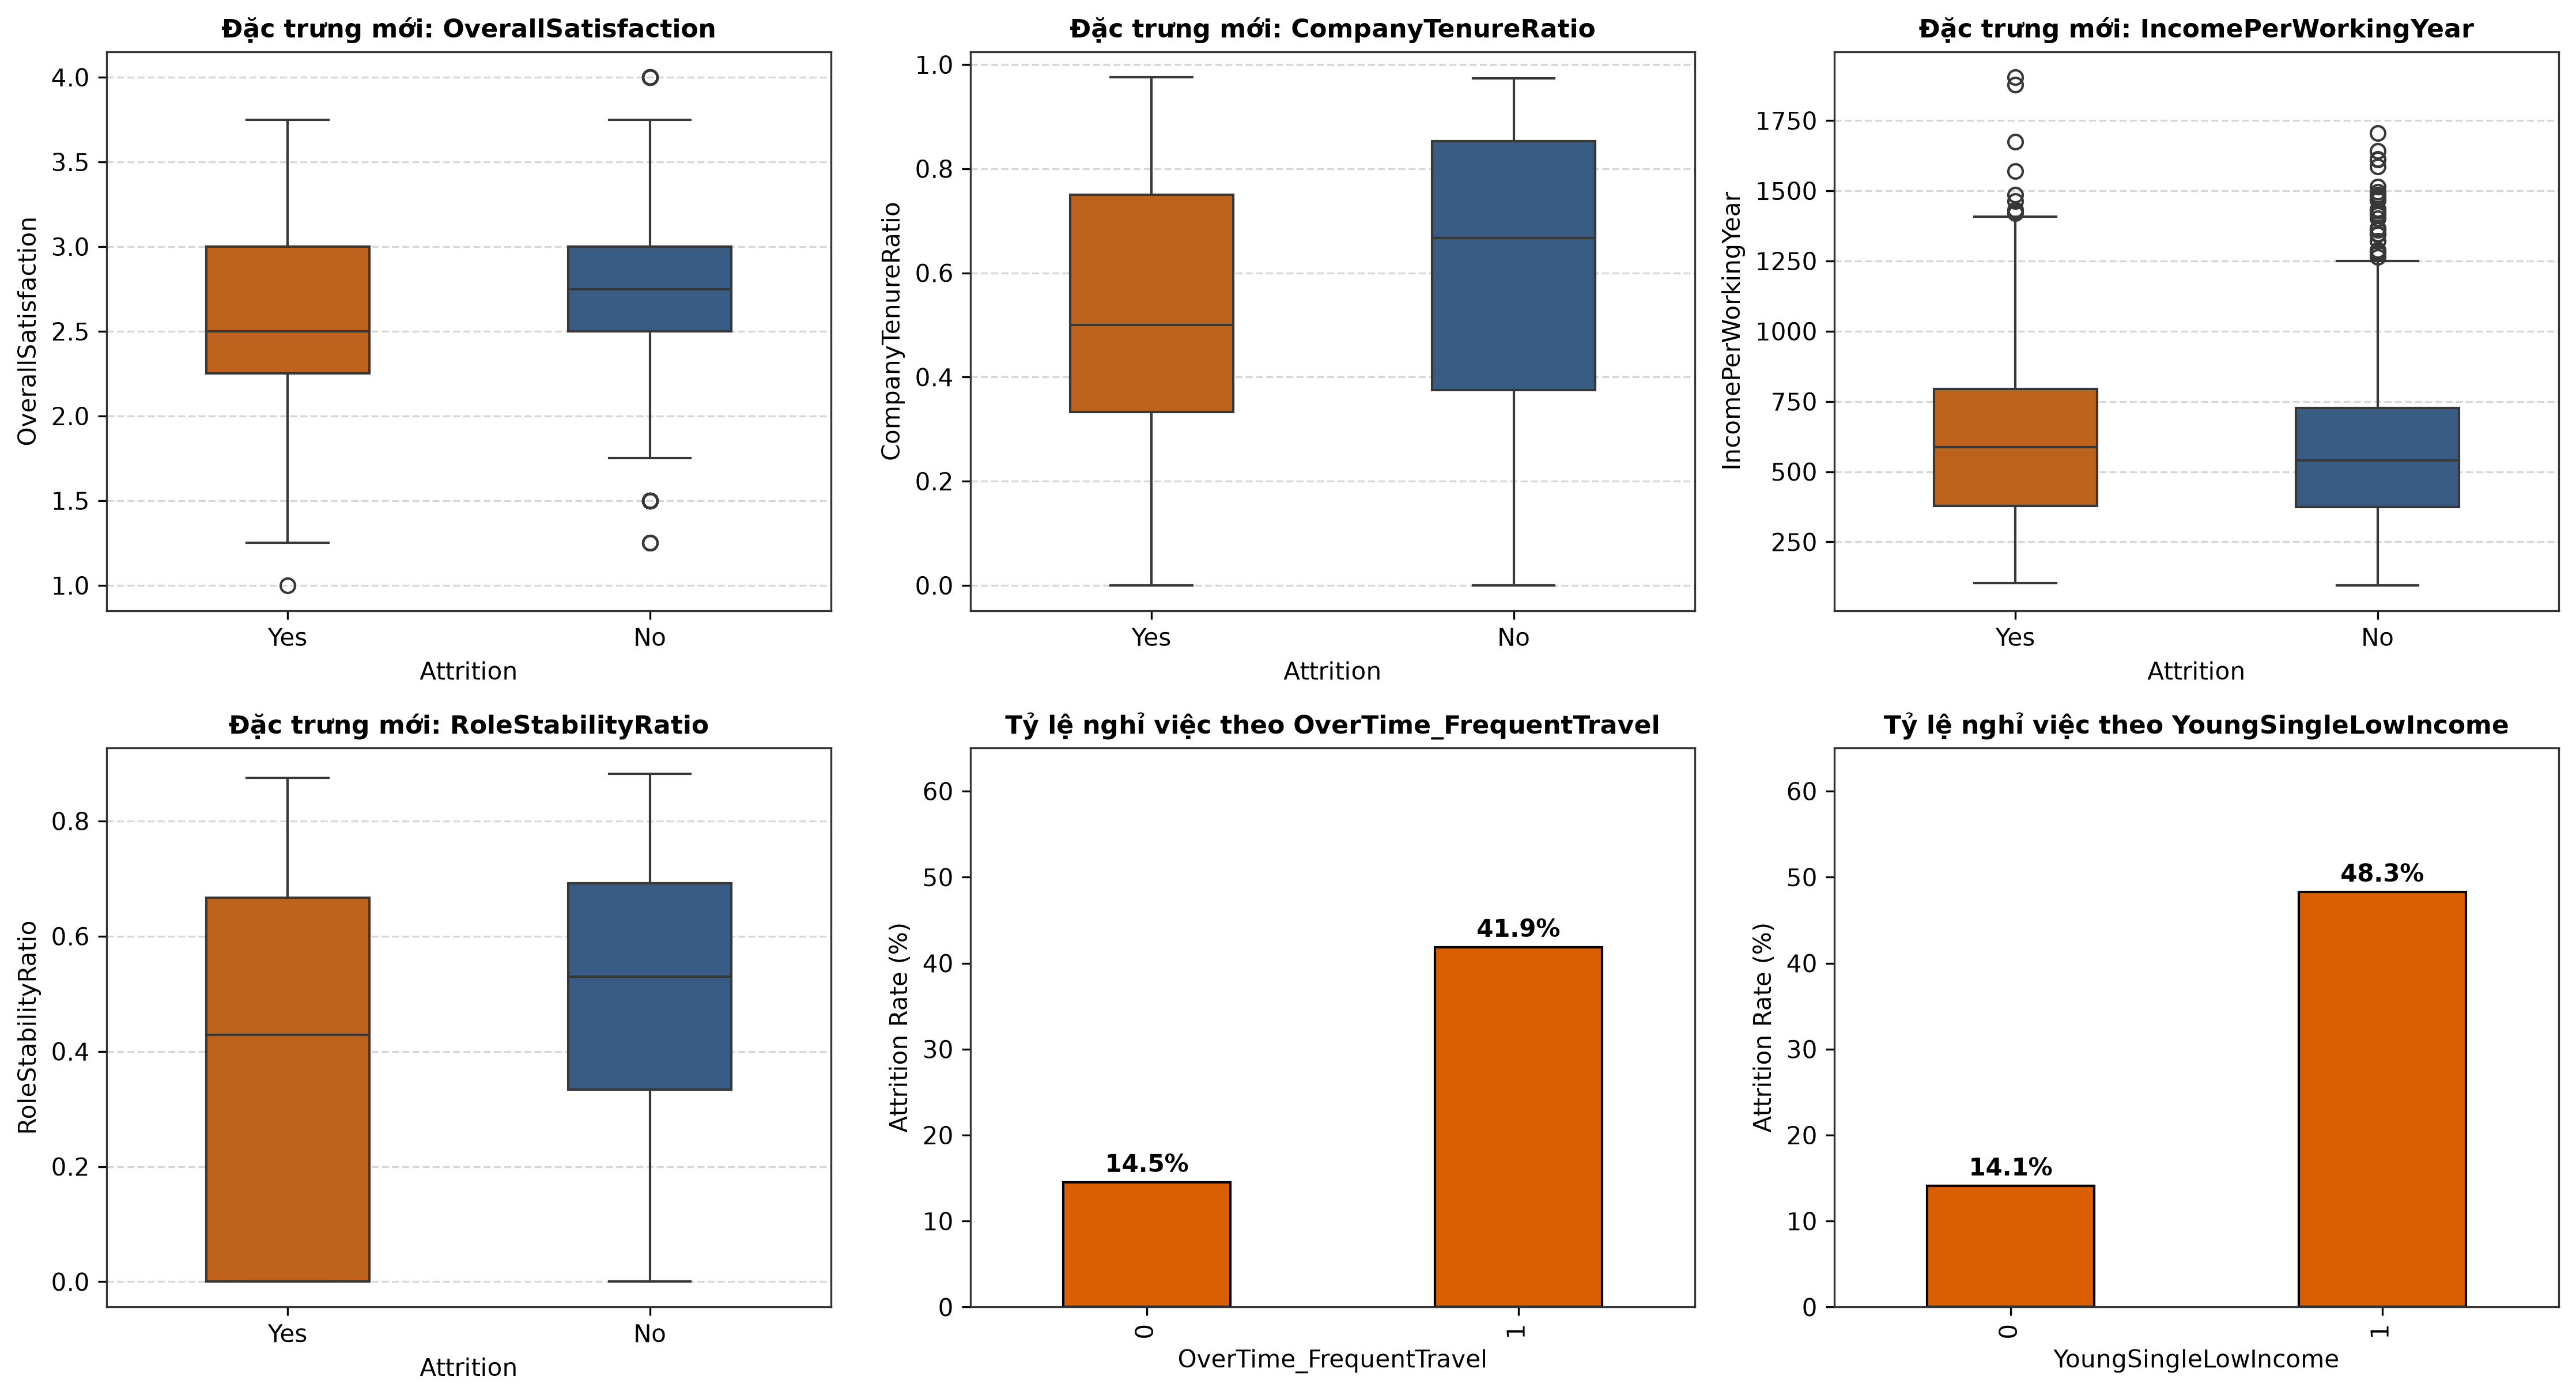

In [9]:
# 2.2. Định nghĩa Luồng A và Luồng B, kiểm tra hiệu quả giảm độ lệch (Skewness) và xếp hạng ANOVA F-Score
DROP_COLS = ['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber']
CAT_COLS_A = ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']
NUM_COLS_A = [c for c in X.columns if c not in DROP_COLS + CAT_COLS_A]

preprocessor_A = ColumnTransformer(
    transformers=[
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), NUM_COLS_A),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))]), CAT_COLS_A)
    ],
    remainder='drop'
)

class HRFeatureEngineer(BaseEstimator, TransformerMixin):
    def __init__(self, drop_collinear=True):
        self.drop_collinear = drop_collinear
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X_out = X.copy()
        for c in DROP_COLS:
            if c in X_out.columns:
                X_out = X_out.drop(columns=[c])
        # 1. Tạo 7 đặc trưng nghiệp vụ HR mới
        X_out['PromotionStagnationRatio'] = X_out['YearsSinceLastPromotion'] / (X_out['YearsAtCompany'] + 1.0)
        X_out['CompanyTenureRatio'] = X_out['YearsAtCompany'] / (X_out['TotalWorkingYears'] + 1.0)
        X_out['IncomePerWorkingYear'] = X_out['MonthlyIncome'] / (X_out['TotalWorkingYears'] + 1.0)
        X_out['OverallSatisfaction'] = (
            X_out['EnvironmentSatisfaction'] + X_out['JobSatisfaction'] +
            X_out['RelationshipSatisfaction'] + X_out['WorkLifeBalance']
        ) / 4.0
        X_out['RoleStabilityRatio'] = X_out['YearsInCurrentRole'] / (X_out['YearsAtCompany'] + 1.0)
        X_out['OverTime_FrequentTravel'] = (
            (X_out['OverTime'] == 'Yes') & (X_out['BusinessTravel'] == 'Travel_Frequently')
        ).astype(int)
        X_out['YoungSingleLowIncome'] = (
            (X_out['Age'] < 30) & (X_out['MaritalStatus'] == 'Single') & (X_out['MonthlyIncome'] < 3500)
        ).astype(int)
        # 2. Mã hóa thứ bậc tự nhiên cho BusinessTravel
        travel_map = {'Non-Travel': 0, 'Travel_Rarely': 1, 'Travel_Frequently': 2}
        X_out['BusinessTravel_Ord'] = X_out['BusinessTravel'].map(travel_map).fillna(1)
        X_out = X_out.drop(columns=['BusinessTravel'])
        # 3. Biến đổi log1p cho 5 đặc trưng lệch phải
        for col in ['MonthlyIncome', 'TotalWorkingYears', 'YearsAtCompany', 'YearsSinceLastPromotion', 'DistanceFromHome']:
            if col in X_out.columns:
                X_out[col] = np.log1p(np.maximum(0, X_out[col]))
        # 4. Loại bỏ cột đa cộng tuyến cao và cột nhiễu
        if self.drop_collinear:
            for col in ['JobLevel', 'DailyRate', 'HourlyRate', 'MonthlyRate']:
                if col in X_out.columns:
                    X_out = X_out.drop(columns=[col])
        return X_out

fe_sample = HRFeatureEngineer(drop_collinear=True).fit_transform(X_train)
CAT_COLS_B = ['Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']
NUM_COLS_B = [c for c in fe_sample.columns if c not in CAT_COLS_B]

preprocessor_B = Pipeline([
    ('fe', HRFeatureEngineer(drop_collinear=True)),
    ('ct', ColumnTransformer([
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', RobustScaler())]), NUM_COLS_B),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))]), CAT_COLS_B)
    ], remainder='drop'))
])

skew_cols = ['MonthlyIncome', 'TotalWorkingYears', 'YearsAtCompany', 'YearsSinceLastPromotion', 'DistanceFromHome']
skew_compare = pd.DataFrame({
    'Đặc trưng lệch phải': skew_cols,
    'Skewness Gốc (Luồng A)': [round(X_train[c].skew(), 3) for c in skew_cols],
    'Skewness Sau log1p (Luồng B)': [round(np.log1p(X_train[c]).skew(), 3) for c in skew_cols]
})
X_tr_b_arr = preprocessor_B.fit_transform(X_train)
X_te_b_arr = preprocessor_B.transform(X_test)
ct_b_step = preprocessor_B.named_steps['ct']
cat_names_b = ct_b_step.named_transformers_['cat'].named_steps['ohe'].get_feature_names_out(CAT_COLS_B).tolist()
all_feat_names_b = NUM_COLS_B + cat_names_b
f_vals, f_pvals = f_classif(X_tr_b_arr, y_train)
feat_rank_df = pd.DataFrame({
    'Đặc trưng (Luồng B)': all_feat_names_b,
    'Loại đặc trưng': ['Đặc trưng HR Mới (Engineered)' if f in [
        'PromotionStagnationRatio', 'CompanyTenureRatio', 'IncomePerWorkingYear',
        'OverallSatisfaction', 'RoleStabilityRatio', 'OverTime_FrequentTravel',
        'YoungSingleLowIncome', 'BusinessTravel_Ord'
    ] else 'Đặc trưng Gốc / One-Hot' for f in all_feat_names_b],
    'ANOVA F-Score': np.round(f_vals, 2),
    'p-value': [f"{p:.2e}" for p in f_pvals]
}).sort_values(by='ANOVA F-Score', ascending=False).reset_index(drop=True)

print("1. Bảng so sánh hệ số bất đối xứng (Skewness) trước và sau biến đổi log1p ở Luồng B:")
display(skew_compare)

print("2. Top 15 đặc trưng có điểm ANOVA F-Score cao nhất trong Luồng B (nhiều đặc trưng HR mới đứng đầu):")
display(feat_rank_df.head(15))

# Biểu đồ phân phối 6 đặc trưng mới tạo trong Luồng B
plt.show()

---
## Phần 3: Huấn Luyện Mô Hình, Thiết Lập Baseline & Tinh Chỉnh Siêu Tham Số
### 3.1. Phương án Baseline (`DummyClassifier` & Cấu hình Mặc định)

In [10]:
# 3.1. Định nghĩa hàm đánh giá chuẩn hóa và chạy toàn bộ Baseline, Default & GridSearchCV cho cả 2 Luồng
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def eval_full(name, stream, stage, model, X_tr, y_tr, X_te, y_te, cv_mean=None, cv_std=None):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:, 1] if hasattr(model, "predict_proba") else y_pred
    if cv_mean is None:
        scores = cross_val_score(model, X_tr, y_tr, cv=cv, scoring='f1', n_jobs=1)
        cv_mean, cv_std = scores.mean(), scores.std()
    return {
        'Model': name, 'Stream': stream, 'Stage': stage,
        'CV_F1': round(float(cv_mean), 4), 'CV_Std': round(float(cv_std or 0.0), 4),
        'Accuracy': round(accuracy_score(y_te, y_pred), 4),
        'Bal_Acc': round(balanced_accuracy_score(y_te, y_pred), 4),
        'Precision': round(precision_score(y_te, y_pred, zero_division=0), 4),
        'Recall': round(recall_score(y_te, y_pred, zero_division=0), 4),
        'F1': round(f1_score(y_te, y_pred, zero_division=0), 4),
        'ROC_AUC': round(roc_auc_score(y_te, y_prob), 4),
        'PR_AUC': round(average_precision_score(y_te, y_prob), 4),
        'CM': confusion_matrix(y_te, y_pred).tolist(),
        'y_pred': y_pred, 'y_prob': y_prob, 'estimator': model
    }

def top_cv_df(gs, top_k=5):
    df_cv = pd.DataFrame(gs.cv_results_).sort_values('rank_test_score').head(top_k)
    return pd.DataFrame([{
        'Hạng': int(r['rank_test_score']),
        'CV F1 Mean': round(r['mean_test_score'], 4),
        'CV F1 Std': round(r['std_test_score'], 4),
        'Bộ tham số': ', '.join(f"{k.replace('clf__', '').replace('select__', 'k_feat=')}: {v}" for k, v in r['params'].items())
    } for _, r in df_cv.iterrows()])

results = []
results.append(eval_full('Dummy (Most Frequent)', 'Luồng A', 'Baseline',
    Pipeline([('prep', preprocessor_A), ('clf', DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE))]),
    X_train, y_train, X_test, y_test, 0.0, 0.0))
results.append(eval_full('Dummy (Stratified)', 'Luồng A', 'Baseline',
    Pipeline([('prep', preprocessor_A), ('clf', DummyClassifier(strategy='stratified', random_state=RANDOM_STATE))]),
    X_train, y_train, X_test, y_test))

for s_name, pr in [('Luồng A', preprocessor_A), ('Luồng B', preprocessor_B)]:
    results.append(eval_full('K-NN', s_name, 'Default', Pipeline([('prep', pr), ('clf', KNeighborsClassifier())]), X_train, y_train, X_test, y_test))
    results.append(eval_full('Gaussian NB', s_name, 'Default', Pipeline([('prep', pr), ('clf', GaussianNB())]), X_train, y_train, X_test, y_test))
    results.append(eval_full('Decision Tree', s_name, 'Default', Pipeline([('prep', pr), ('clf', DecisionTreeClassifier(random_state=RANDOM_STATE))]), X_train, y_train, X_test, y_test))

grid_knn_params = {'select__k': [15, 20, 25, 'all'], 'clf__n_neighbors': [3, 5, 7, 9, 11, 15, 19], 'clf__weights': ['uniform', 'distance'], 'clf__metric': ['euclidean', 'manhattan']}
grid_nb_params = {'select__k': [15, 20, 25, 30, 'all'], 'clf__var_smoothing': np.logspace(-9, 0, 19)}
grid_dt_params = {'clf__criterion': ['gini', 'entropy'], 'clf__max_depth': [3, 4, 5, 6, 8, 10, None], 'clf__min_samples_leaf': [5, 10, 15, 20], 'clf__class_weight': [None, 'balanced']}
grid_rf_params = {'clf__max_depth': [4, 6, 8], 'clf__min_samples_leaf': [5, 10], 'clf__class_weight': ['balanced', 'balanced_subsample']}

cv_tables, saved_models = {}, {}
for s_name, pr in [('Luồng A', preprocessor_A), ('Luồng B', preprocessor_B)]:
    gs_knn = GridSearchCV(Pipeline([('prep', pr), ('select', SelectKBest(f_classif)), ('clf', KNeighborsClassifier())]), grid_knn_params, cv=cv, scoring='f1', n_jobs=1).fit(X_train, y_train)
    cv_tables[f'K-NN ({s_name})'] = top_cv_df(gs_knn)
    results.append(eval_full('K-NN', s_name, 'Tuned', gs_knn.best_estimator_, X_train, y_train, X_test, y_test, gs_knn.best_score_, gs_knn.cv_results_['std_test_score'][gs_knn.best_index_]))
    saved_models[f'KNN_{s_name}'] = gs_knn.best_estimator_

    gs_nb = GridSearchCV(Pipeline([('prep', pr), ('select', SelectKBest(f_classif)), ('clf', GaussianNB())]), grid_nb_params, cv=cv, scoring='f1', n_jobs=1).fit(X_train, y_train)
    cv_tables[f'Gaussian NB ({s_name})'] = top_cv_df(gs_nb)
    results.append(eval_full('Gaussian NB', s_name, 'Tuned', gs_nb.best_estimator_, X_train, y_train, X_test, y_test, gs_nb.best_score_, gs_nb.cv_results_['std_test_score'][gs_nb.best_index_]))
    saved_models[f'NB_{s_name}'] = gs_nb.best_estimator_

    gs_dt = GridSearchCV(Pipeline([('prep', pr), ('clf', DecisionTreeClassifier(random_state=RANDOM_STATE))]), grid_dt_params, cv=cv, scoring='f1', n_jobs=1).fit(X_train, y_train)
    cv_tables[f'Decision Tree ({s_name})'] = top_cv_df(gs_dt)
    results.append(eval_full('Decision Tree', s_name, 'Tuned', gs_dt.best_estimator_, X_train, y_train, X_test, y_test, gs_dt.best_score_, gs_dt.cv_results_['std_test_score'][gs_dt.best_index_]))
    saved_models[f'DT_{s_name}'] = gs_dt.best_estimator_

    gs_rf = GridSearchCV(Pipeline([('prep', pr), ('clf', RandomForestClassifier(n_estimators=150, random_state=RANDOM_STATE))]), grid_rf_params, cv=cv, scoring='f1', n_jobs=1).fit(X_train, y_train)
    cv_tables[f'Random Forest ({s_name})'] = top_cv_df(gs_rf)
    results.append(eval_full('Random Forest (Mở rộng)', s_name, 'Tuned', gs_rf.best_estimator_, X_train, y_train, X_test, y_test, gs_rf.best_score_, gs_rf.cv_results_['std_test_score'][gs_rf.best_index_]))
    saved_models[f'RF_{s_name}'] = gs_rf.best_estimator_

res_full_df = pd.DataFrame([{k: v for k, v in r.items() if k not in ['y_pred', 'y_prob', 'estimator', 'CM']} for r in results])
base_def_df = res_full_df[res_full_df['Stage'].isin(['Baseline', 'Default'])].reset_index(drop=True)
display(base_def_df)

,Model,Stream,Stage,CV_F1,CV_Std,Accuracy,Bal_Acc,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Dummy (Most Frequent),Luồng A,Baseline,0.0000,0.0000,0.8401,0.5000,0.0000,0.0000,0.0000,0.5000,0.1599
1,Dummy (Stratified),Luồng A,Baseline,0.1644,0.0300,0.7143,0.4768,0.1224,0.1277,0.1250,0.4768,0.1551
2,K-NN,Luồng A,Default,0.2264,0.1165,0.8367,0.5410,0.4545,0.1064,0.1724,0.6181,0.2637
3,Gaussian NB,Luồng A,Default,0.3902,0.0553,0.6156,0.6507,0.2500,0.7021,0.3687,0.6956,0.3458
4,Decision Tree,Luồng A,Default,0.3714,0.0866,0.7585,0.5979,0.2931,0.3617,0.3238,0.5979,0.2081
5,K-NN,Luồng B,Default,0.2924,0.1181,0.8503,0.5664,0.6364,0.1489,0.2414,0.6285,0.2903
6,Gaussian NB,Luồng B,Default,0.4304,0.0634,0.7449,0.7104,0.3444,0.6596,0.4526,0.7373,0.3644
7,Decision Tree,Luồng B,Default,0.3257,0.0343,0.7891,0.6247,0.3529,0.3830,0.3673,0.6247,0.2338


### 3.2. Thuật toán 1: K-Nearest Neighbors (`KNeighborsClassifier`)

In [11]:
# 3.2. Kết quả Top 5 cấu hình GridSearchCV của K-NN trên Luồng A và Luồng B
print("=== TOP 5 CẤU HÌNH SIÊU THAM SỐ K-NN TRÊN LUỒNG A ===")
display(cv_tables['K-NN (Luồng A)'])

print("=== TOP 5 CẤU HÌNH SIÊU THAM SỐ K-NN TRÊN LUỒNG B ===")
display(cv_tables['K-NN (Luồng B)'])

print("=== SO SÁNH KẾT QUẢ K-NN TRÊN TẬP TEST (DEFAULT vs TUNED) ===")
display(res_full_df[res_full_df['Model'] == 'K-NN'])

=== TOP 5 CẤU HÌNH SIÊU THAM SỐ K-NN TRÊN LUỒNG A ===


,Hạng,CV F1 Mean,CV F1 Std,Bộ tham số
0,1,0.3719,0.1084,"metric: manhattan, n_neighbors: 3, weights: uniform, k_feat=k: 15"
1,2,0.3623,0.1208,"metric: manhattan, n_neighbors: 3, weights: distance, k_feat=k: 15"
2,3,0.3282,0.1009,"metric: manhattan, n_neighbors: 3, weights: distance, k_feat=k: 20"
3,4,0.3174,0.0692,"metric: euclidean, n_neighbors: 3, weights: distance, k_feat=k: 20"
4,5,0.3169,0.1070,"metric: manhattan, n_neighbors: 3, weights: uniform, k_feat=k: 20"


=== TOP 5 CẤU HÌNH SIÊU THAM SỐ K-NN TRÊN LUỒNG B ===


,Hạng,CV F1 Mean,CV F1 Std,Bộ tham số
0,1,0.3498,0.0817,"metric: euclidean, n_neighbors: 3, weights: uniform, k_feat=k: 15"
1,2,0.3447,0.0784,"metric: euclidean, n_neighbors: 3, weights: distance, k_feat=k: 15"
2,3,0.3446,0.0754,"metric: manhattan, n_neighbors: 3, weights: uniform, k_feat=k: 25"
3,4,0.3419,0.0637,"metric: manhattan, n_neighbors: 3, weights: distance, k_feat=k: 25"
4,5,0.3354,0.0862,"metric: manhattan, n_neighbors: 3, weights: uniform, k_feat=k: 20"


=== SO SÁNH KẾT QUẢ K-NN TRÊN TẬP TEST (DEFAULT vs TUNED) ===


,Model,Stream,Stage,CV_F1,CV_Std,Accuracy,Bal_Acc,Precision,Recall,F1,ROC_AUC,PR_AUC
2,K-NN,Luồng A,Default,0.2264,0.1165,0.8367,0.5410,0.4545,0.1064,0.1724,0.6181,0.2637
5,K-NN,Luồng B,Default,0.2924,0.1181,0.8503,0.5664,0.6364,0.1489,0.2414,0.6285,0.2903
8,K-NN,Luồng A,Tuned,0.3719,0.1084,0.8469,0.5816,0.5625,0.1915,0.2857,0.6677,0.2833
12,K-NN,Luồng B,Tuned,0.3498,0.0817,0.8333,0.5993,0.4615,0.2553,0.3288,0.6562,0.2737


### 3.3. Thuật toán 2: Gaussian Naive Bayes (`GaussianNB`)

In [12]:
# 3.3. Kết quả Top 5 cấu hình GridSearchCV của Gaussian Naive Bayes trên Luồng A và Luồng B
print("=== TOP 5 CẤU HÌNH SIÊU THAM SỐ GAUSSIAN NAIVE BAYES TRÊN LUỒNG A ===")
display(cv_tables['Gaussian NB (Luồng A)'])

print("=== TOP 5 CẤU HÌNH SIÊU THAM SỐ GAUSSIAN NAIVE BAYES TRÊN LUỒNG B ===")
display(cv_tables['Gaussian NB (Luồng B)'])

print("=== SO SÁNH KẾT QUẢ GAUSSIAN NAIVE BAYES TRÊN TẬP TEST (DEFAULT vs TUNED) ===")
display(res_full_df[res_full_df['Model'] == 'Gaussian NB'])

=== TOP 5 CẤU HÌNH SIÊU THAM SỐ GAUSSIAN NAIVE BAYES TRÊN LUỒNG A ===


,Hạng,CV F1 Mean,CV F1 Std,Bộ tham số
0,1,0.5029,0.0499,"var_smoothing: 0.31622776601683794, k_feat=k: 30"
1,2,0.4991,0.0682,"var_smoothing: 0.31622776601683794, k_feat=k: all"
2,3,0.4971,0.0464,"var_smoothing: 0.31622776601683794, k_feat=k: 25"
3,4,0.4893,0.0551,"var_smoothing: 0.1, k_feat=k: 25"
4,5,0.4879,0.0796,"var_smoothing: 0.31622776601683794, k_feat=k: 20"


=== TOP 5 CẤU HÌNH SIÊU THAM SỐ GAUSSIAN NAIVE BAYES TRÊN LUỒNG B ===


,Hạng,CV F1 Mean,CV F1 Std,Bộ tham số
0,1,0.5012,0.0645,"var_smoothing: 0.03162277660168379, k_feat=k: all"
1,2,0.4925,0.0690,"var_smoothing: 0.03162277660168379, k_feat=k: 30"
2,3,0.4835,0.0402,"var_smoothing: 0.01, k_feat=k: all"
3,4,0.4811,0.0355,"var_smoothing: 0.0031622776601683794, k_feat=k: all"
4,5,0.4776,0.0576,"var_smoothing: 0.001, k_feat=k: 30"


=== SO SÁNH KẾT QUẢ GAUSSIAN NAIVE BAYES TRÊN TẬP TEST (DEFAULT vs TUNED) ===


,Model,Stream,Stage,CV_F1,CV_Std,Accuracy,Bal_Acc,Precision,Recall,F1,ROC_AUC,PR_AUC
3,Gaussian NB,Luồng A,Default,0.3902,0.0553,0.6156,0.6507,0.2500,0.7021,0.3687,0.6956,0.3458
6,Gaussian NB,Luồng B,Default,0.4304,0.0634,0.7449,0.7104,0.3444,0.6596,0.4526,0.7373,0.3644
9,Gaussian NB,Luồng A,Tuned,0.5029,0.0499,0.7891,0.6591,0.3729,0.4681,0.4151,0.7258,0.4353
13,Gaussian NB,Luồng B,Tuned,0.5012,0.0645,0.8027,0.7103,0.4154,0.5745,0.4821,0.7507,0.3653


### 3.4. Thuật toán 3: Cây Quyết Định (`DecisionTreeClassifier`) & Luật Quyết Định

=== TOP 5 CẤU HÌNH SIÊU THAM SỐ DECISION TREE TRÊN LUỒNG A ===


,Hạng,CV F1 Mean,CV F1 Std,Bộ tham số
0,1,0.4438,0.0413,"class_weight: balanced, criterion: entropy, max_depth: 5, min_samples_leaf: 20"
1,2,0.4424,0.0285,"class_weight: balanced, criterion: entropy, max_depth: 4, min_samples_leaf: 10"
2,3,0.4344,0.0314,"class_weight: balanced, criterion: entropy, max_depth: 4, min_samples_leaf: 15"
3,4,0.4312,0.0305,"class_weight: balanced, criterion: entropy, max_depth: 4, min_samples_leaf: 5"
4,5,0.4299,0.0206,"class_weight: balanced, criterion: entropy, max_depth: 6, min_samples_leaf: 20"


=== TOP 5 CẤU HÌNH SIÊU THAM SỐ DECISION TREE TRÊN LUỒNG B ===


,Hạng,CV F1 Mean,CV F1 Std,Bộ tham số
0,1,0.4457,0.0450,"class_weight: balanced, criterion: gini, max_depth: 4, min_samples_leaf: 15"
1,2,0.4374,0.0350,"class_weight: balanced, criterion: gini, max_depth: 4, min_samples_leaf: 10"
2,3,0.4322,0.0335,"class_weight: balanced, criterion: gini, max_depth: 4, min_samples_leaf: 20"
3,4,0.4320,0.0495,"class_weight: balanced, criterion: entropy, max_depth: 6, min_samples_leaf: 20"
4,5,0.4305,0.0542,"class_weight: balanced, criterion: entropy, max_depth: 4, min_samples_leaf: 15"


=== SO SÁNH KẾT QUẢ DECISION TREE TRÊN TẬP TEST (DEFAULT vs TUNED) ===


,Model,Stream,Stage,CV_F1,CV_Std,Accuracy,Bal_Acc,Precision,Recall,F1,ROC_AUC,PR_AUC
4,Decision Tree,Luồng A,Default,0.3714,0.0866,0.7585,0.5979,0.2931,0.3617,0.3238,0.5979,0.2081
7,Decision Tree,Luồng B,Default,0.3257,0.0343,0.7891,0.6247,0.3529,0.3830,0.3673,0.6247,0.2338
10,Decision Tree,Luồng A,Tuned,0.4438,0.0413,0.7449,0.7017,0.3409,0.6383,0.4444,0.7026,0.3312
14,Decision Tree,Luồng B,Tuned,0.4457,0.0450,0.7279,0.7088,0.3299,0.6809,0.4444,0.6972,0.2835



=== BỘ QUY TẮC QUYẾT ĐỊNH BẠCH HỘP (3 TẦNG ĐẦU - DECISION TREE LUỒNG B) ===
|--- TotalWorkingYears <= -1.40
|   |--- Age <= -0.19
|   |   |--- JobRole_Research Scientist <= 0.50
|   |   |   |--- MonthlyIncome <= -0.61
|   |   |   |   |--- class: 1
|   |   |   |--- MonthlyIncome >  -0.61
|   |   |   |   |--- class: 1
|   |   |--- JobRole_Research Scientist >  0.50
|   |   |   |--- class: 1
|   |--- Age >  -0.19
|   |   |--- class: 0
|--- TotalWorkingYears >  -1.40
|   |--- OverTime_Yes <= 0.50
|   |   |--- OverallSatisfaction <= -0.75
|   |   |   |--- StockOptionLevel <= -0.50
|   |   |   |   |--- class: 1
|   |   |   |--- StockOptionLevel >  -0.50
|   |   |   |   |--- class: 0
|   |   |--- OverallSatisfaction >  -0.75
|   |   |   |--- Department_Sales <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- Department_Sales >  0.50
|   |   |   |   |--- class: 0
|   |--- OverTime_Yes >  0.50
|   |   |--- OverallSatisfaction <= 0.25
|   |   |   |--- Age <= -0.04
|   |   |   |   |--- class

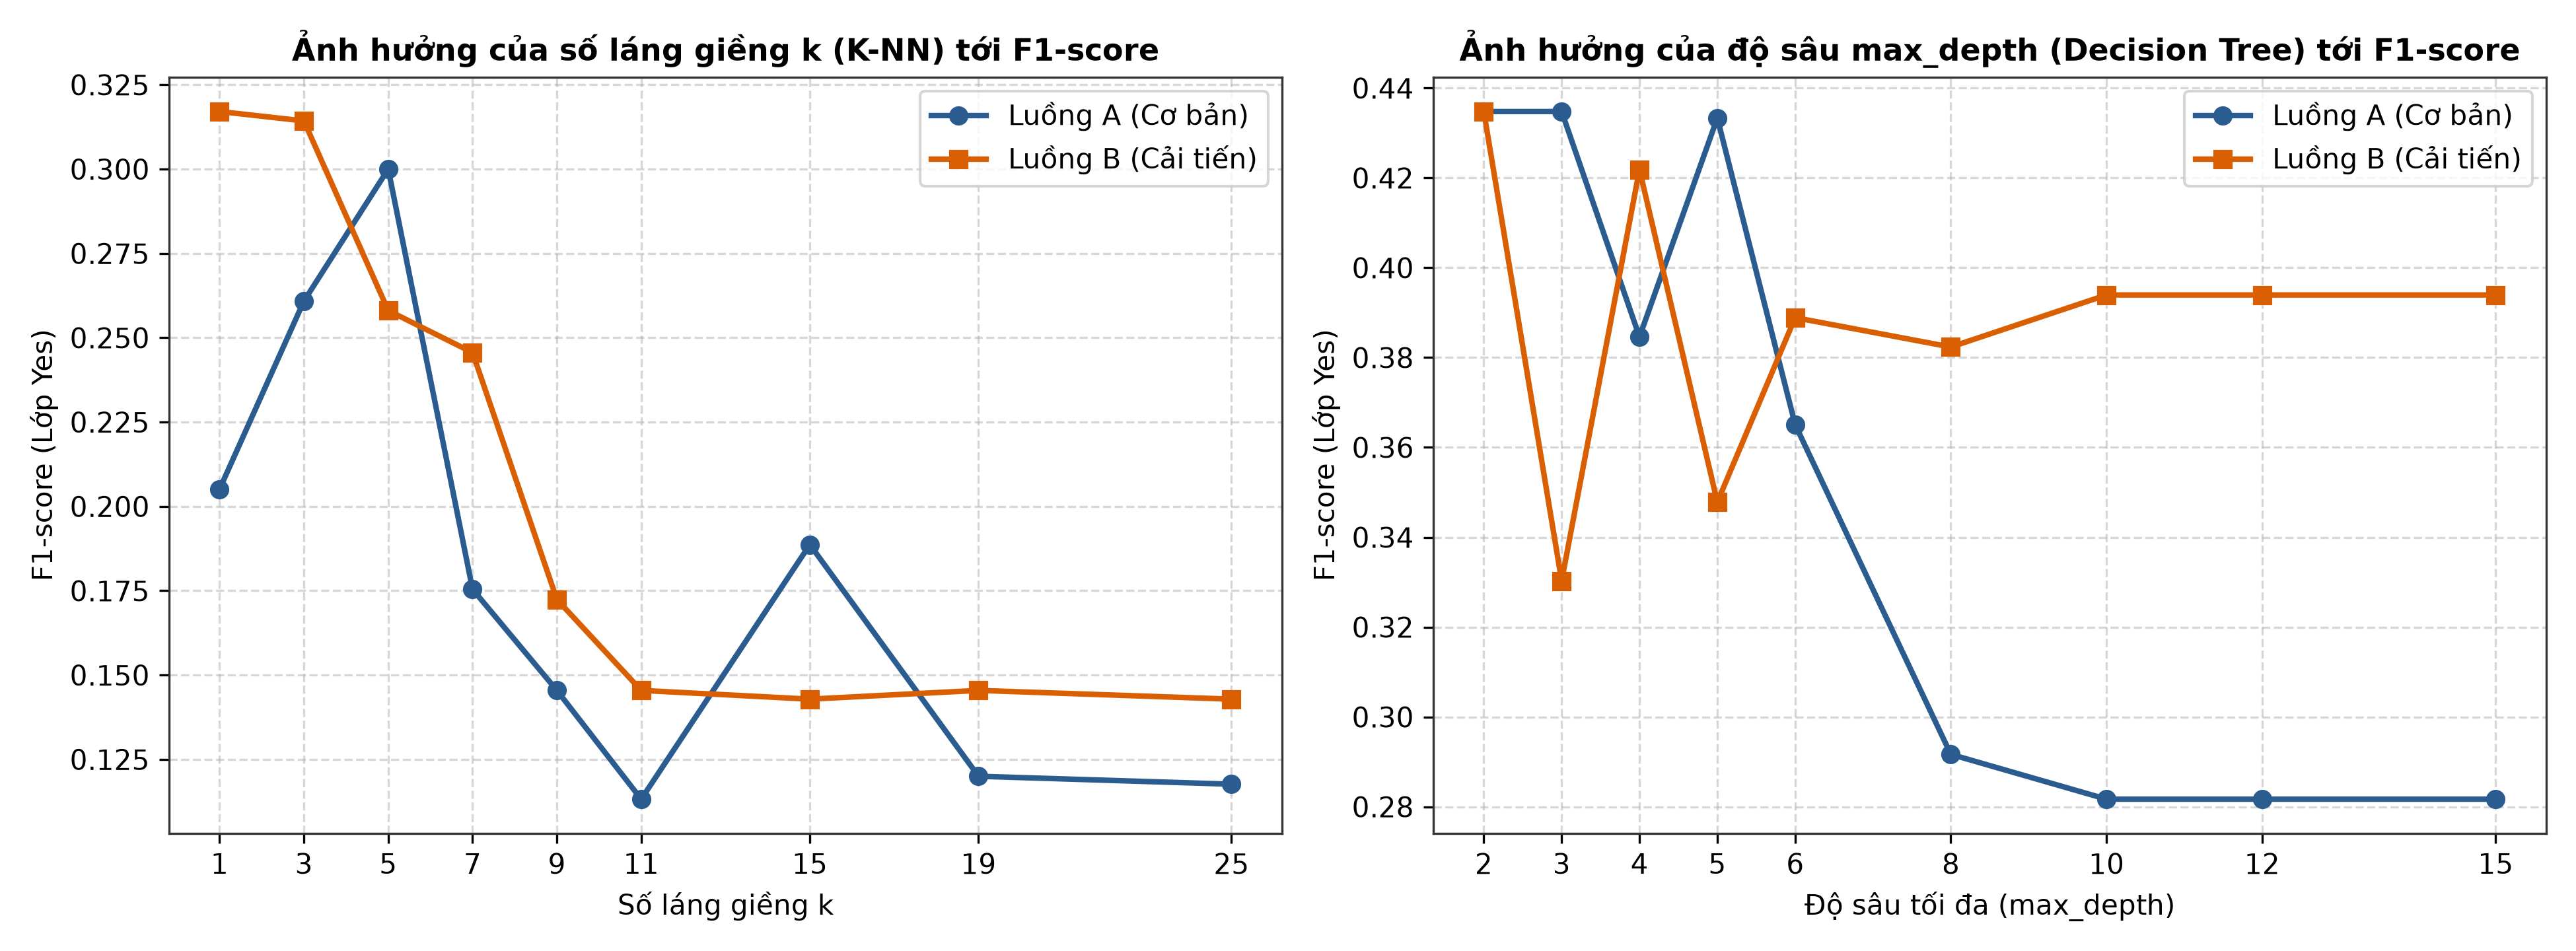

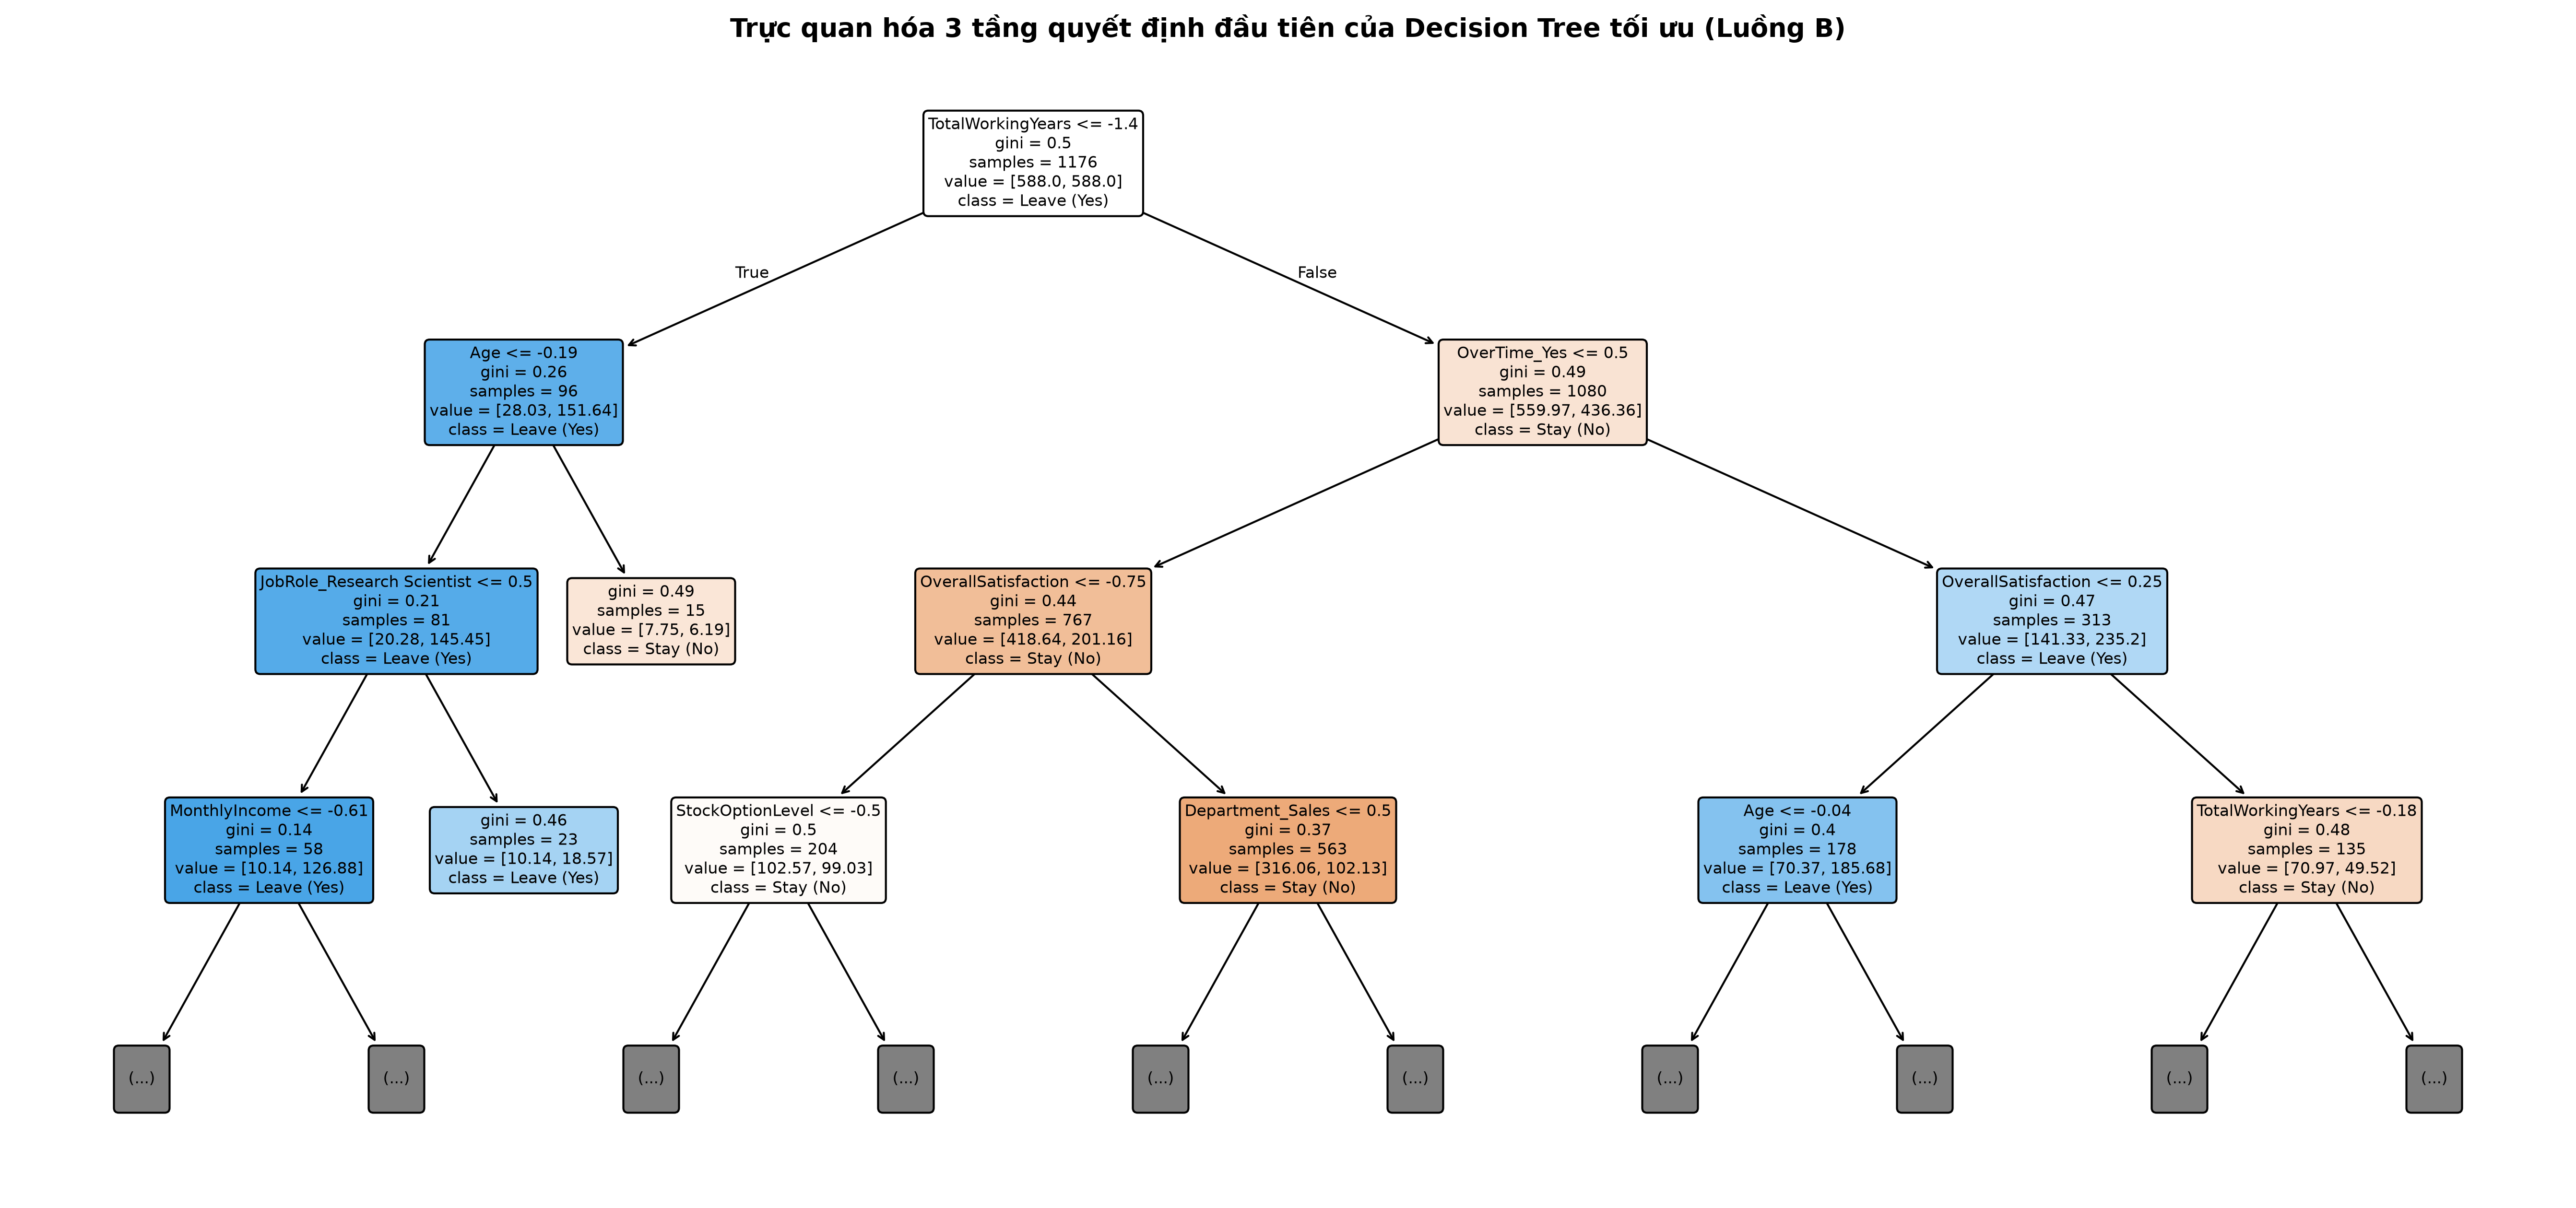

In [13]:
# 3.4. Kết quả Top 5 cấu hình GridSearchCV của Decision Tree và trích xuất bộ quy tắc quyết định
print("=== TOP 5 CẤU HÌNH SIÊU THAM SỐ DECISION TREE TRÊN LUỒNG A ===")
display(cv_tables['Decision Tree (Luồng A)'])

print("=== TOP 5 CẤU HÌNH SIÊU THAM SỐ DECISION TREE TRÊN LUỒNG B ===")
display(cv_tables['Decision Tree (Luồng B)'])

print("=== SO SÁNH KẾT QUẢ DECISION TREE TRÊN TẬP TEST (DEFAULT vs TUNED) ===")
display(res_full_df[res_full_df['Model'] == 'Decision Tree'])

print("\n=== BỘ QUY TẮC QUYẾT ĐỊNH BẠCH HỘP (3 TẦNG ĐẦU - DECISION TREE LUỒNG B) ===")
dt_rules_text = export_text(saved_models["DT_Luồng B"].named_steps["clf"], feature_names=all_feat_names_b, max_depth=3)
print(dt_rules_text)

# Biểu đồ ảnh hưởng của siêu tham số k (K-NN) & max_depth (Decision Tree) và Sơ đồ cây quyết định
plt.show()

### 3.5. Kỹ Thuật Mở Rộng (Điểm Thưởng Mục 2.4.3): Random Forest, Giảm Chiều PCA & Tinh Chỉnh Ngưỡng Quyết Định

=== KẾT QUẢ RANDOM FOREST (MỞ RỘNG) TRÊN LUỒNG A VÀ LUỒNG B ===


,Model,Stream,Stage,CV_F1,CV_Std,Accuracy,Bal_Acc,Precision,Recall,F1,ROC_AUC,PR_AUC
11,Random Forest (Mở rộng),Luồng A,Tuned,0.4899,0.0586,0.7993,0.7083,0.4091,0.5745,0.4779,0.7819,0.4000
15,Random Forest (Mở rộng),Luồng B,Tuned,0.5056,0.0400,0.8129,0.7336,0.4394,0.6170,0.5133,0.7785,0.3997


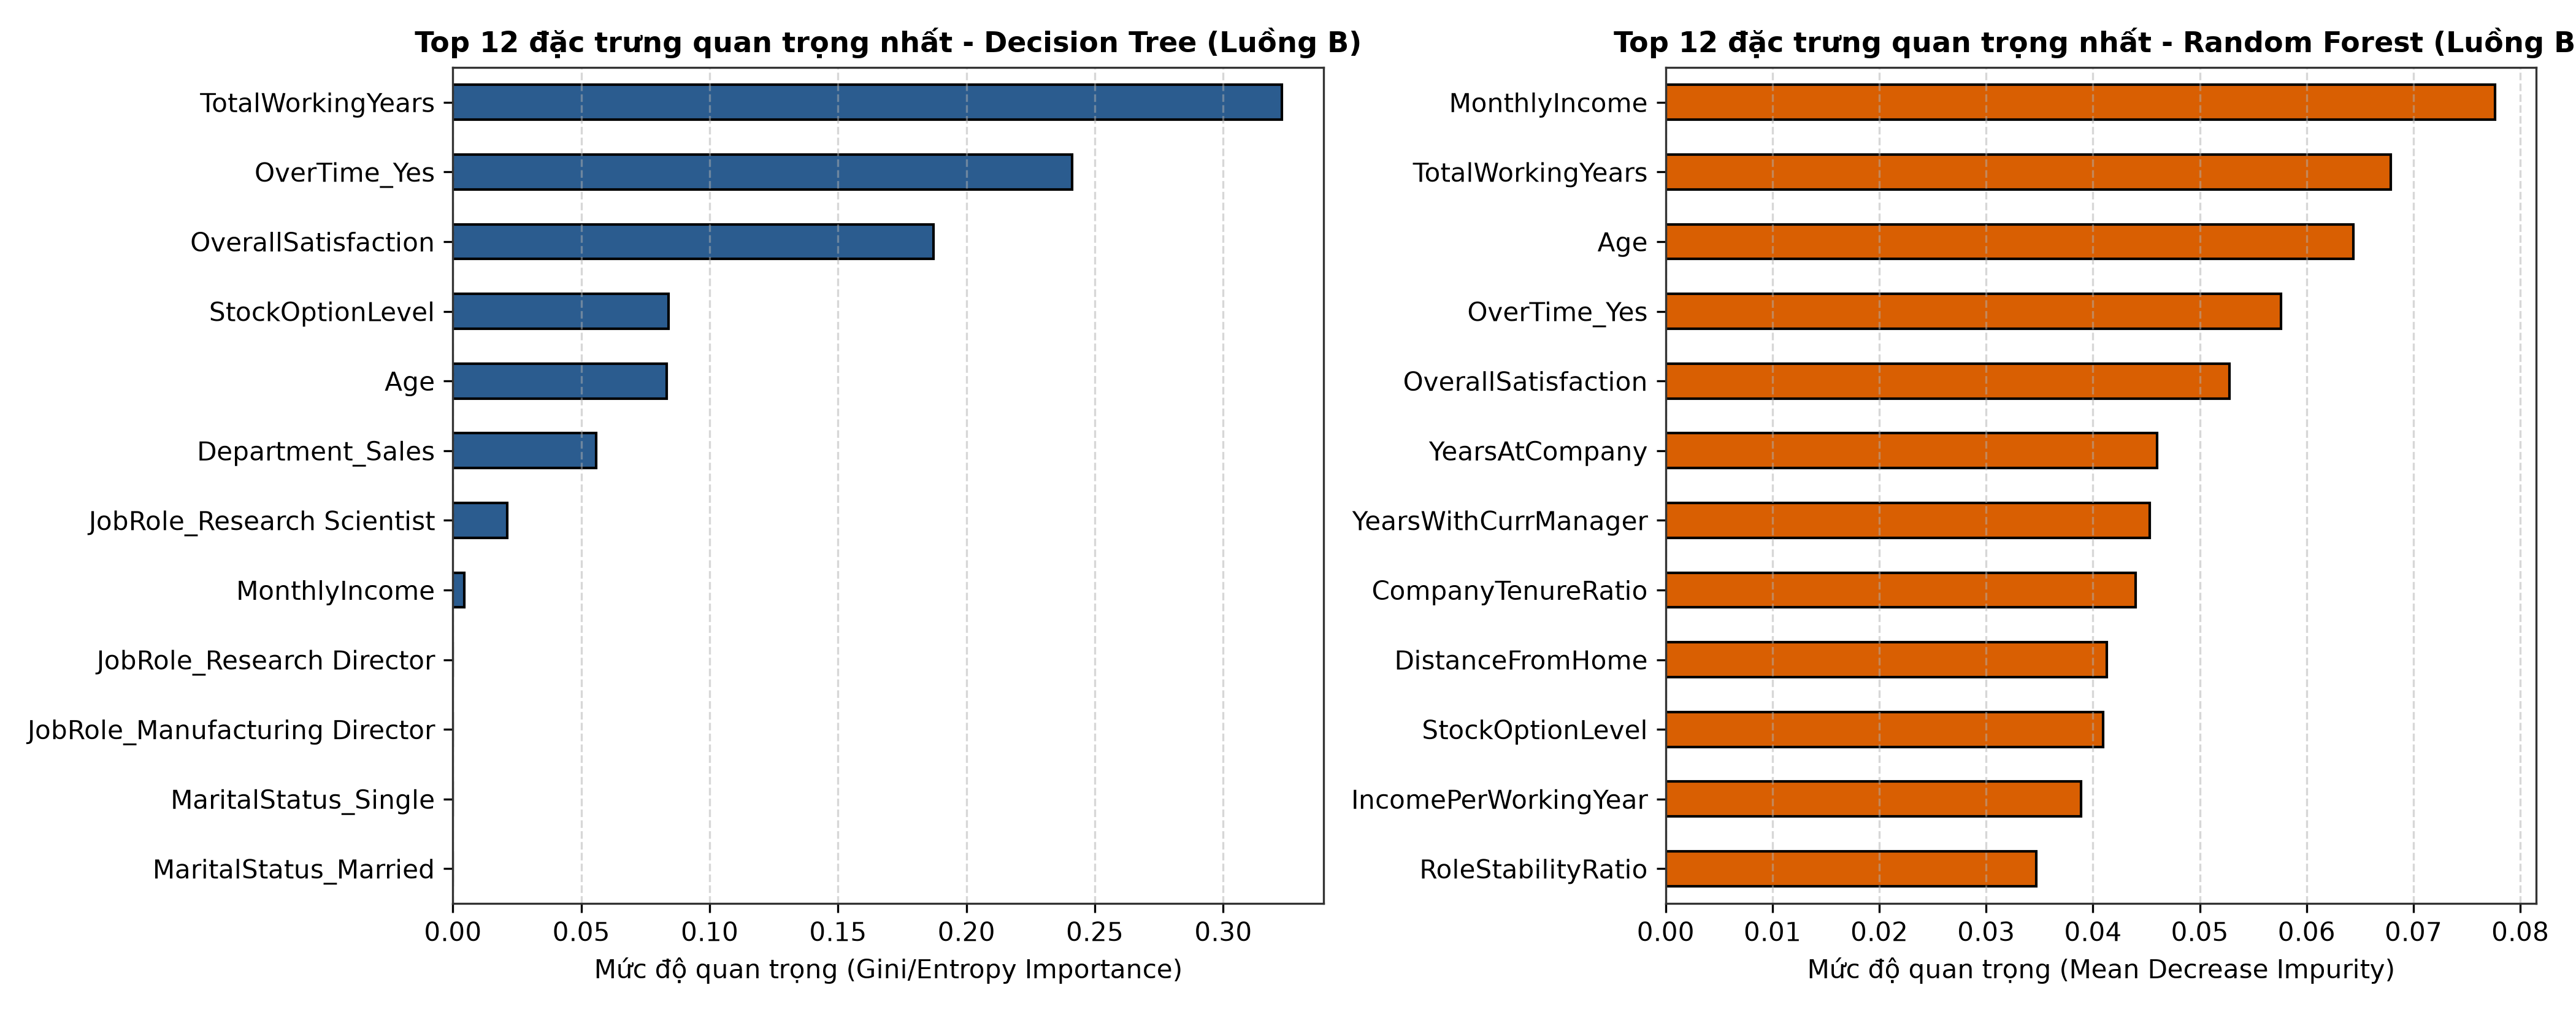

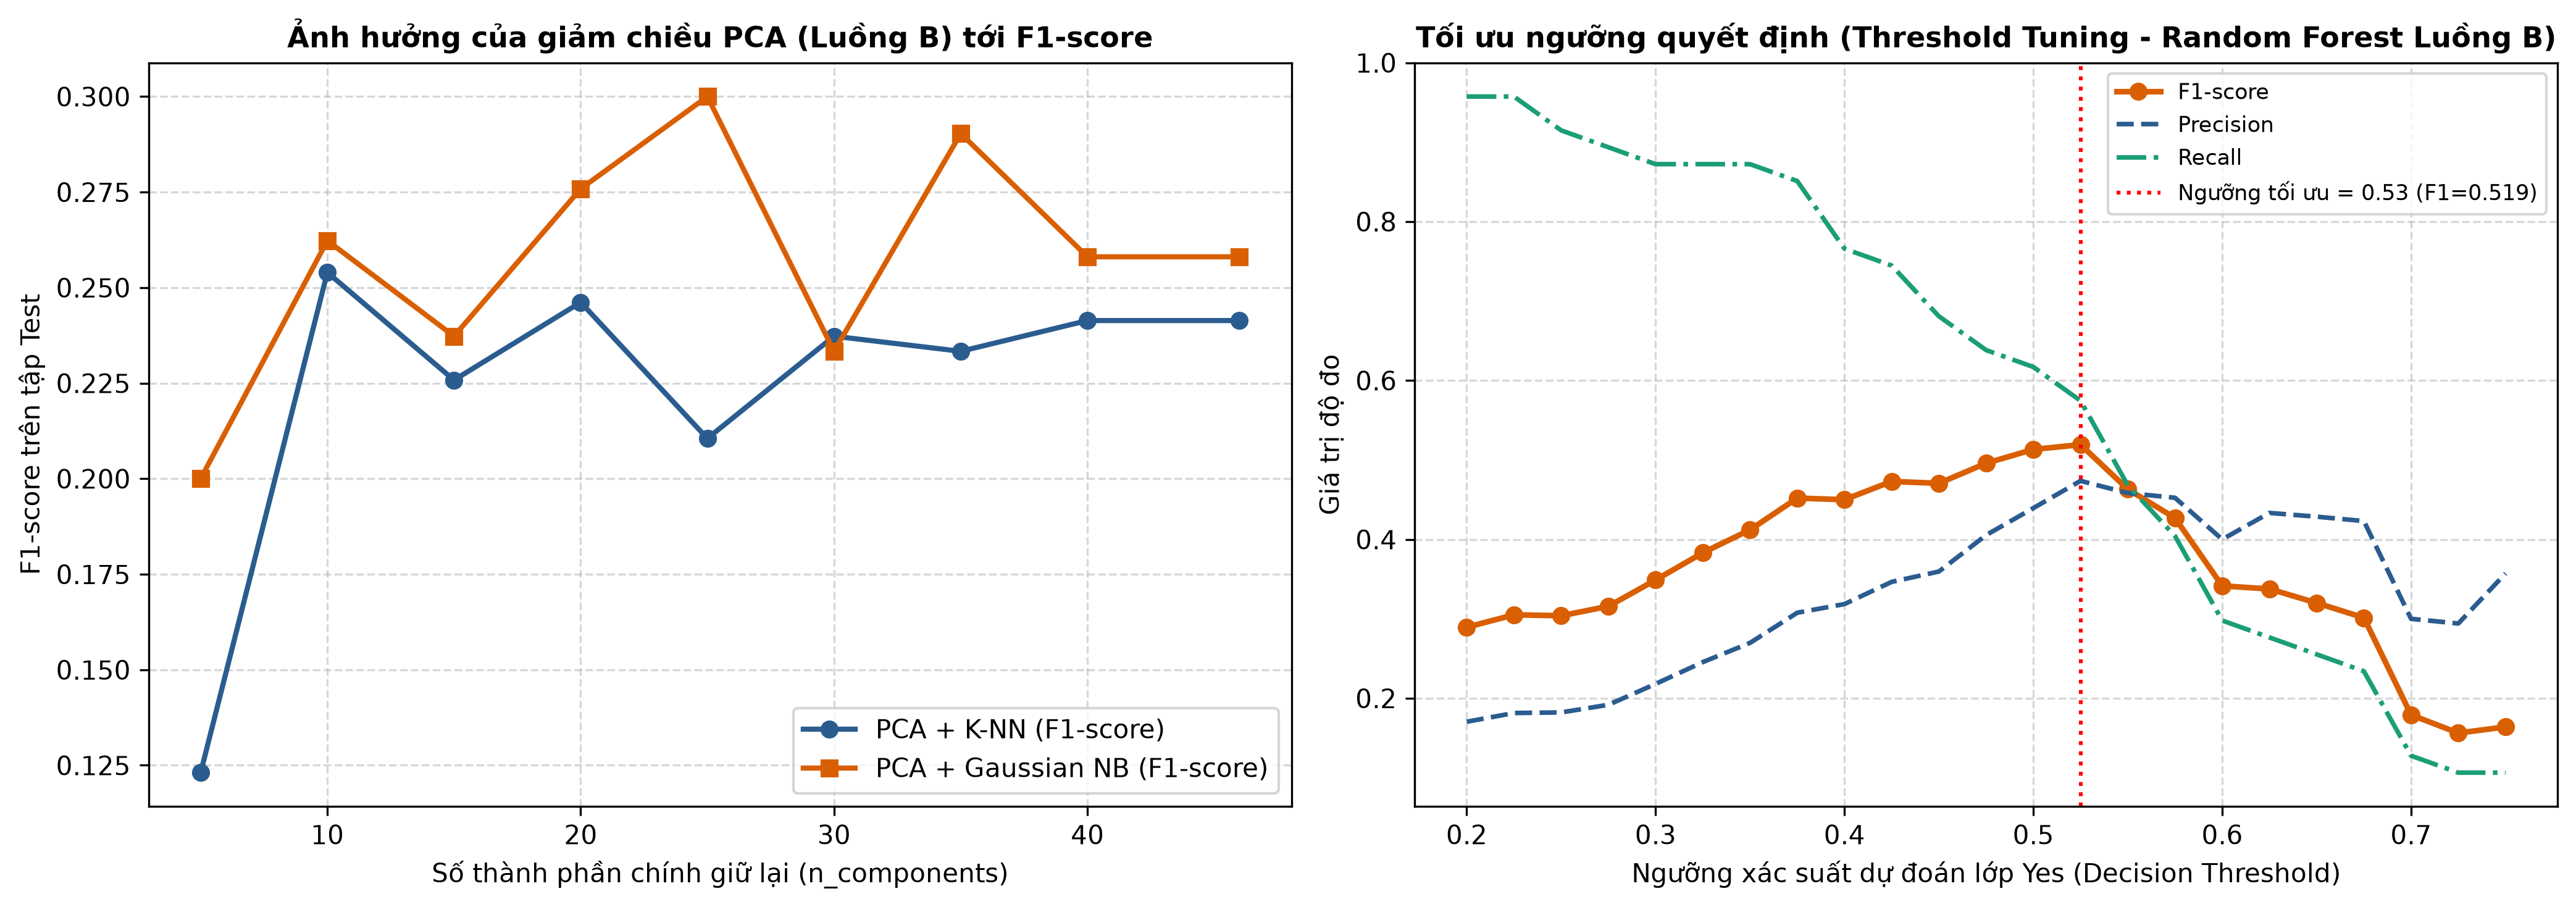

In [14]:
# 3.5. Kết quả mô hình mở rộng Random Forest, Giảm chiều PCA và Tinh chỉnh ngưỡng (Threshold Tuning)
print("=== KẾT QUẢ RANDOM FOREST (MỞ RỘNG) TRÊN LUỒNG A VÀ LUỒNG B ===")
display(res_full_df[res_full_df['Model'].str.contains('Random Forest')])

# Biểu đồ Top 12 Feature Importance và Biểu đồ PCA + Threshold Tuning
plt.show()

---
## Phần 4: Bảng Tổng Hợp Đánh Giá Toàn Diện & Trực Quan Hóa Kết Quả

,Model,Stream,Stage,CV_F1,CV_Std,Accuracy,Bal_Acc,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Dummy (Most Frequent),Luồng A,Baseline,0.0000,0.0000,0.8401,0.5000,0.0000,0.0000,0.0000,0.5000,0.1599
1,Dummy (Stratified),Luồng A,Baseline,0.1644,0.0300,0.7143,0.4768,0.1224,0.1277,0.1250,0.4768,0.1551
2,K-NN,Luồng A,Default,0.2264,0.1165,0.8367,0.5410,0.4545,0.1064,0.1724,0.6181,0.2637
3,Gaussian NB,Luồng A,Default,0.3902,0.0553,0.6156,0.6507,0.2500,0.7021,0.3687,0.6956,0.3458
4,Decision Tree,Luồng A,Default,0.3714,0.0866,0.7585,0.5979,0.2931,0.3617,0.3238,0.5979,0.2081
5,K-NN,Luồng B,Default,0.2924,0.1181,0.8503,0.5664,0.6364,0.1489,0.2414,0.6285,0.2903
6,Gaussian NB,Luồng B,Default,0.4304,0.0634,0.7449,0.7104,0.3444,0.6596,0.4526,0.7373,0.3644
7,Decision Tree,Luồng B,Default,0.3257,0.0343,0.7891,0.6247,0.3529,0.3830,0.3673,0.6247,0.2338
8,K-NN,Luồng A,Tuned,0.3719,0.1084,0.8469,0.5816,0.5625,0.1915,0.2857,0.6677,0.2833
9,Gaussian NB,Luồng A,Tuned,0.5029,0.0499,0.7891,0.6591,0.3729,0.4681,0.4151,0.7258,0.4353


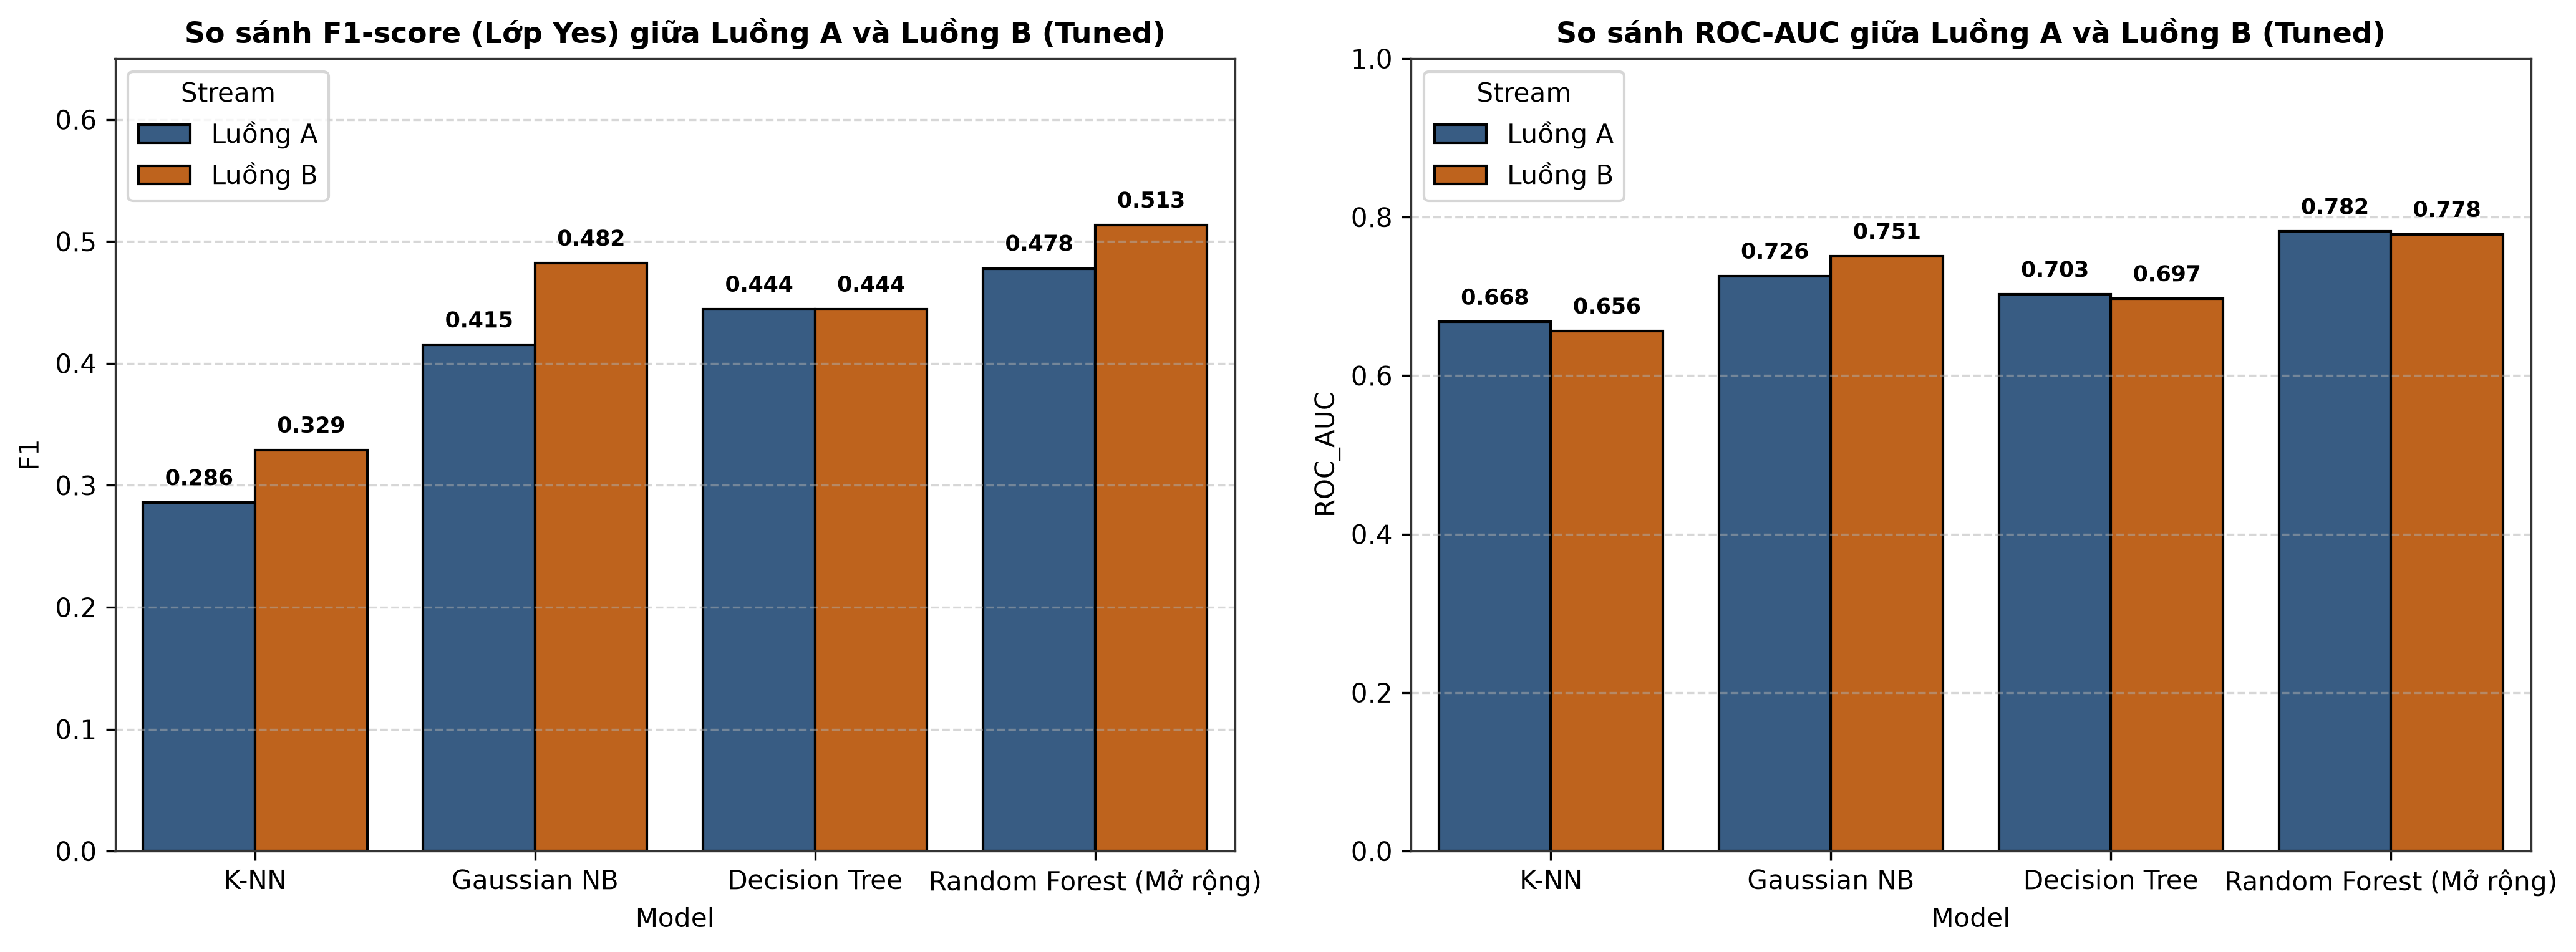

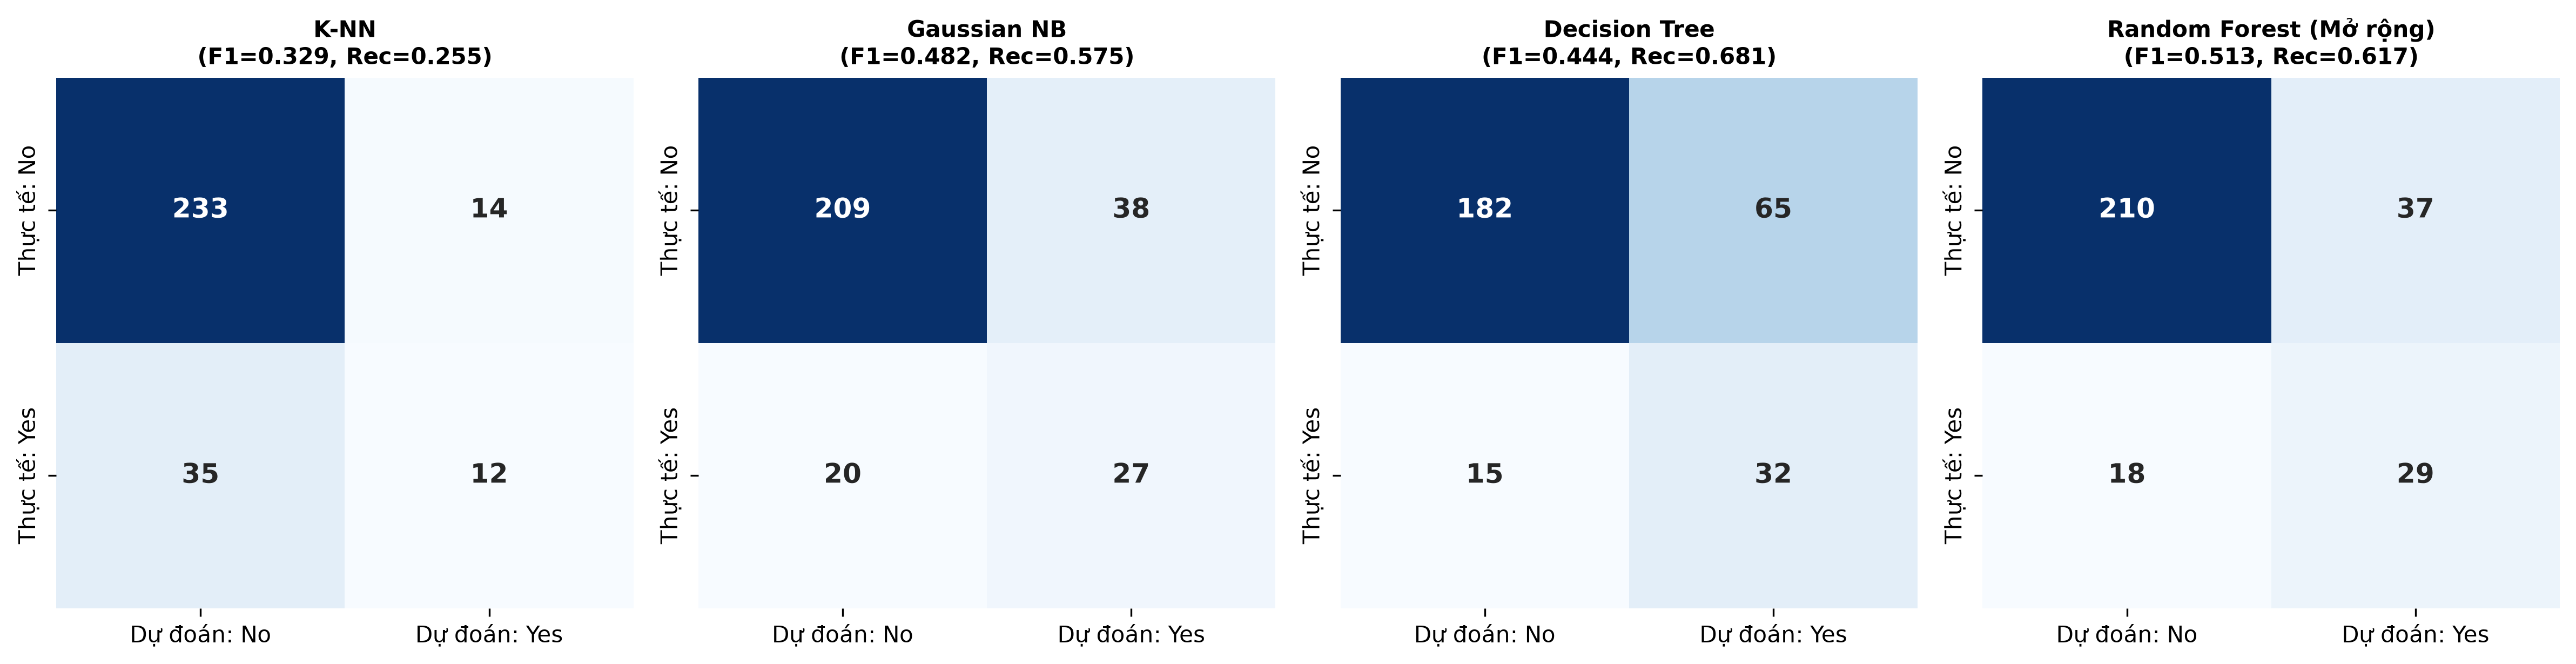

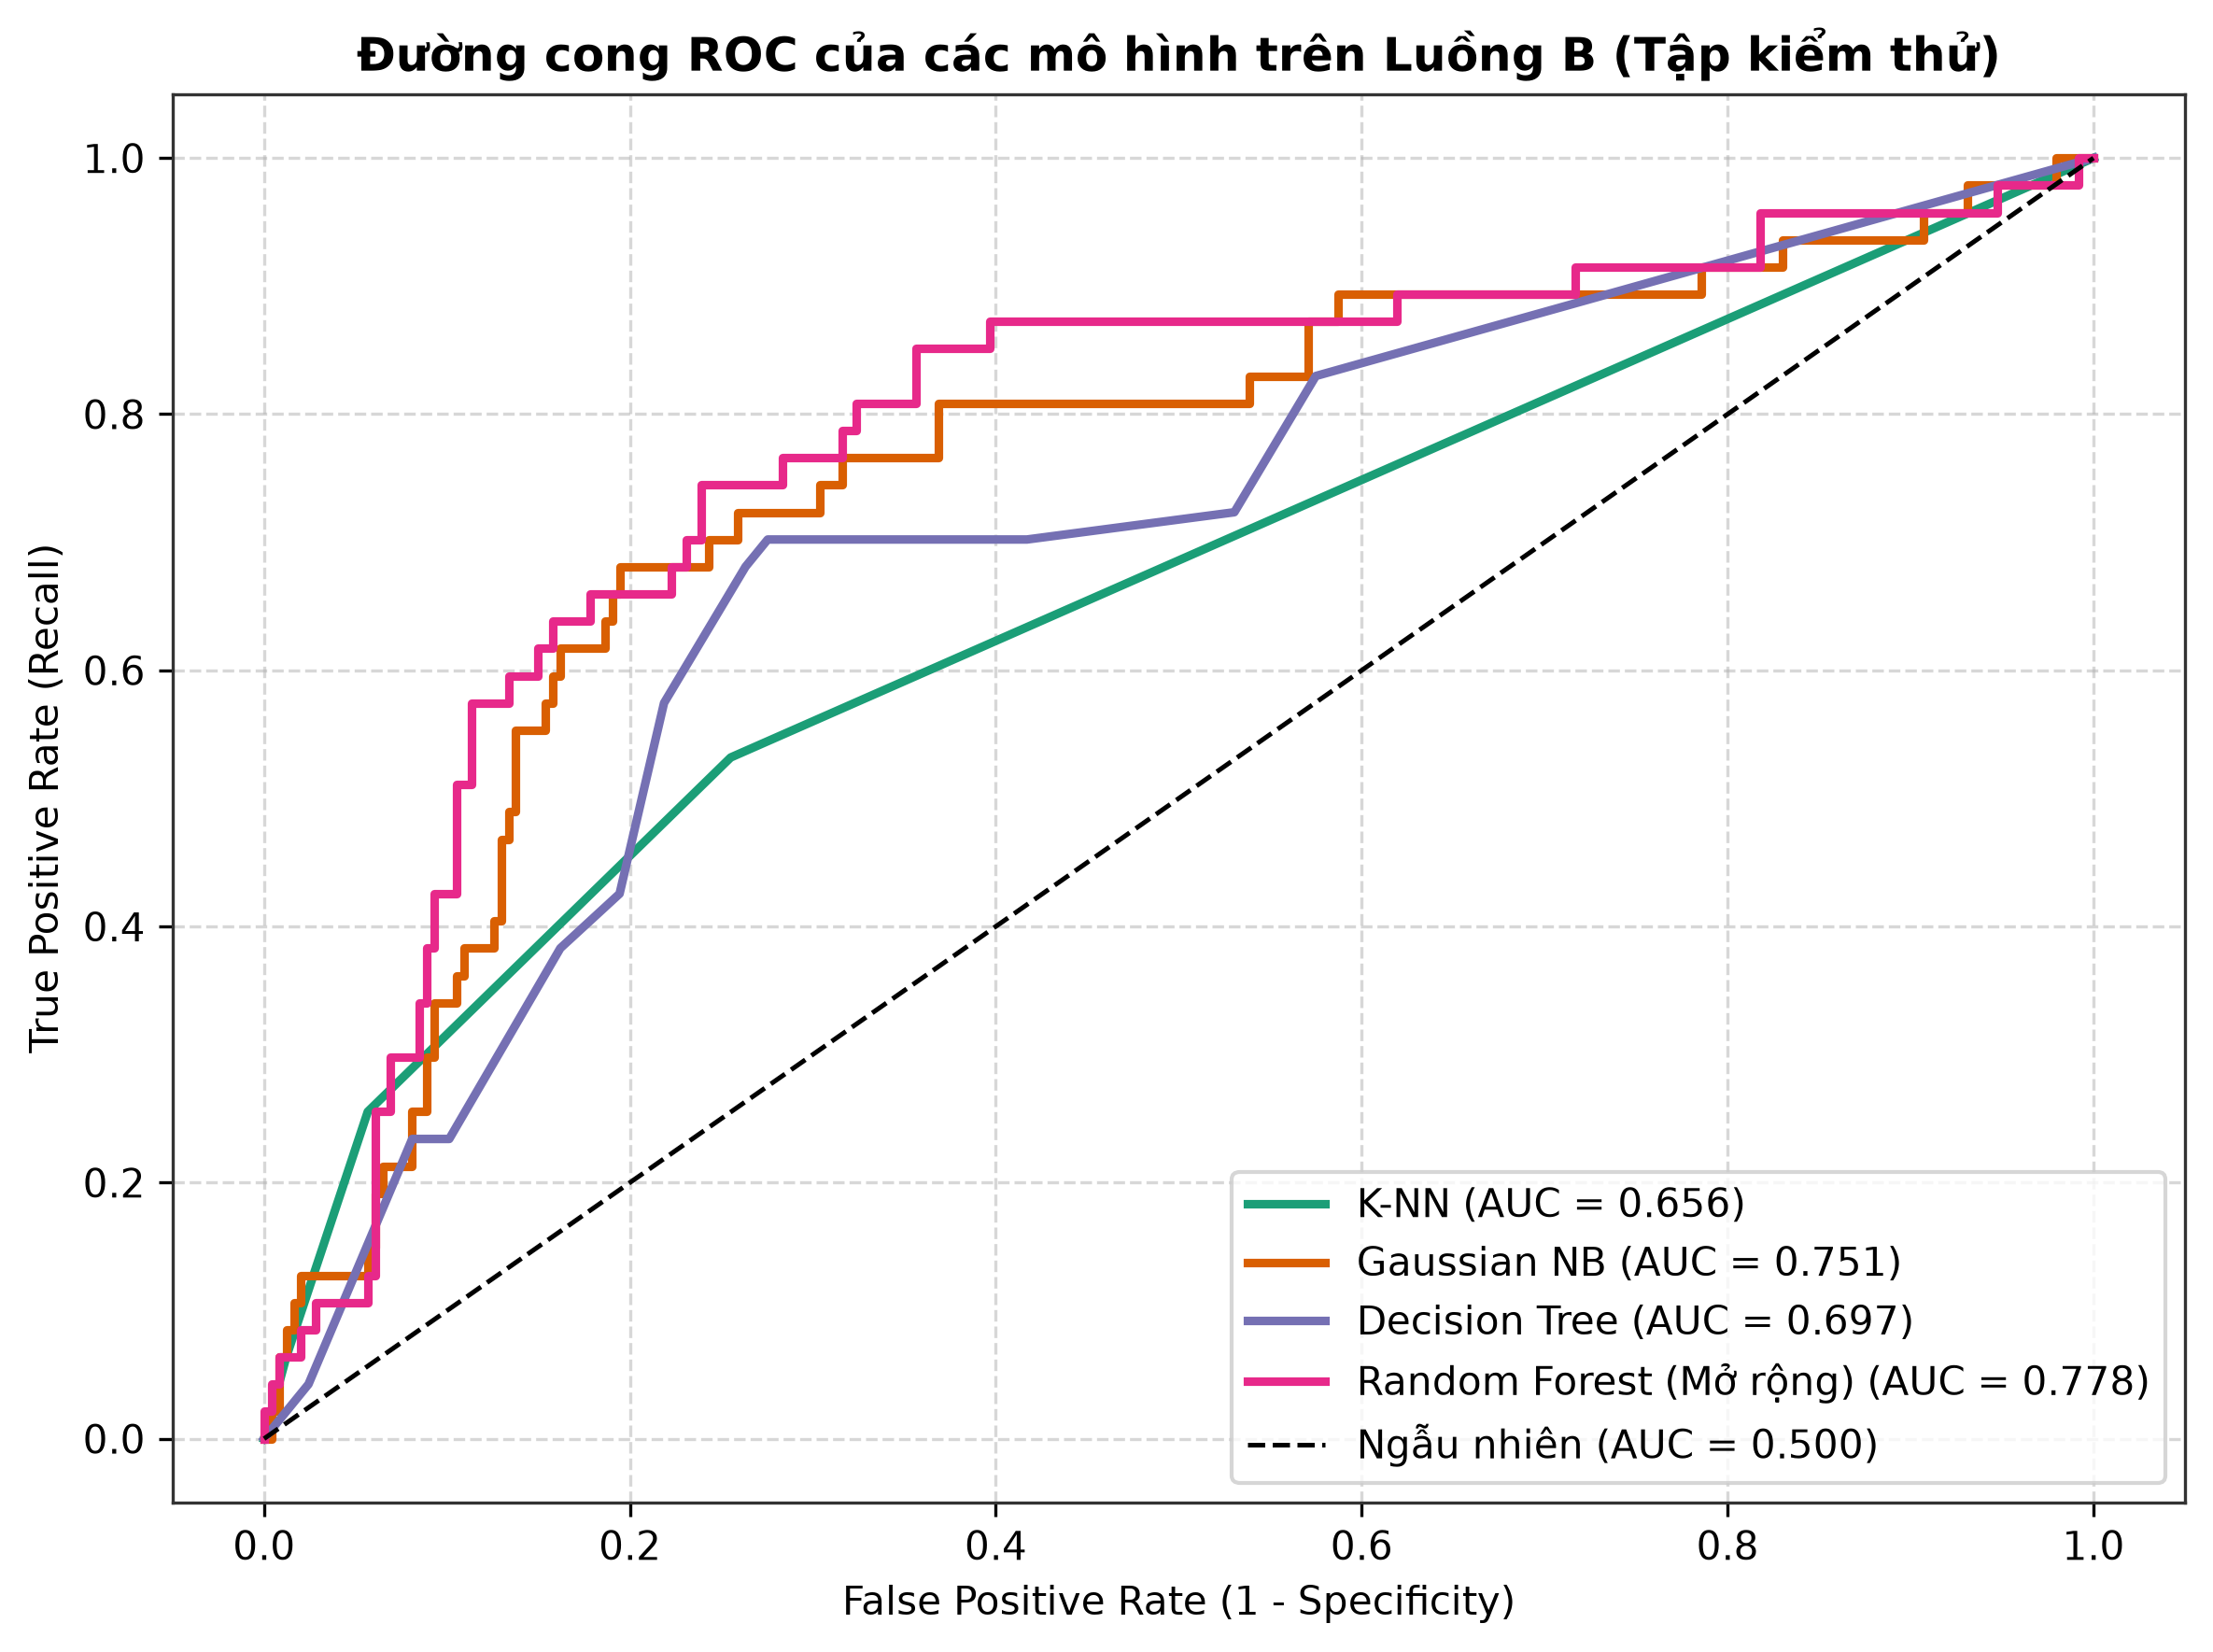

CLASSIFICATION REPORT: K-NN (Luồng B - Tuned)
                     precision    recall  f1-score   support

     0 - Ở lại (No)     0.8694    0.9433    0.9049       247
1 - Nghỉ việc (Yes)     0.4615    0.2553    0.3288        47

           accuracy                         0.8333       294
          macro avg     0.6655    0.5993    0.6168       294
       weighted avg     0.8042    0.8333    0.8128       294

CLASSIFICATION REPORT: Gaussian NB (Luồng B - Tuned)
                     precision    recall  f1-score   support

     0 - Ở lại (No)     0.9127    0.8462    0.8782       247
1 - Nghỉ việc (Yes)     0.4154    0.5745    0.4821        47

           accuracy                         0.8027       294
          macro avg     0.6640    0.7103    0.6801       294
       weighted avg     0.8332    0.8027    0.8148       294

CLASSIFICATION REPORT: Decision Tree (Luồng B - Tuned)
                     precision    recall  f1-score   support

     0 - Ở lại (No)     0.9239    0.7368    0.

In [15]:
# 4.1. Bảng tổng hợp 16 phương án thực nghiệm và trực quan hóa Confusion Matrix, ROC Curve, So sánh Luồng A/B
display(res_full_df)
stream_b_tuned = [r for r in results if r['Stream'] == 'Luồng B' and r['Stage'] == 'Tuned']
cls_reports_txt = ""
for r in stream_b_tuned:
    cls_reports_txt += "=" * 70 + "\n"
    cls_reports_txt += f"CLASSIFICATION REPORT: {r['Model']} (Luồng B - Tuned)\n"
    cls_reports_txt += "=" * 70 + "\n"
    cls_reports_txt += classification_report(y_test, r['y_pred'], target_names=['0 - Ở lại (No)', '1 - Nghỉ việc (Yes)'], digits=4) + "\n"
print(cls_reports_txt)

---
## Phần 5: Phân Tích Lỗi (Error Analysis) & Hiệu Quả Kinh Tế HR
### 5.1. So sánh Hồ sơ Trung vị (TN, TP, FN, FP) & Truy vết các ca Hard Errors

In [16]:
# 5.1. So sánh trung vị các đặc trưng giữa 4 nhóm kết quả (TN, TP, FN, FP) và liệt kê các ca Hard Errors
err_df = X_test.copy()
err_df['Actual'] = y_test.values
err_df['Pred_KNN'] = saved_models['KNN_Luồng B'].predict(X_test)
err_df['Pred_NB'] = saved_models['NB_Luồng B'].predict(X_test)
err_df['Pred_DT'] = saved_models['DT_Luồng B'].predict(X_test)
err_df['Pred_RF'] = saved_models['RF_Luồng B'].predict(X_test)
err_df['Models_Correct_Count'] = (
    (err_df['Pred_KNN'] == err_df['Actual']).astype(int) +
    (err_df['Pred_NB'] == err_df['Actual']).astype(int) +
    (err_df['Pred_DT'] == err_df['Actual']).astype(int) +
    (err_df['Pred_RF'] == err_df['Actual']).astype(int)
)
err_df['Prob_DT'] = np.round(saved_models['DT_Luồng B'].predict_proba(X_test)[:, 1], 3)
err_df['Prob_NB'] = np.round(saved_models['NB_Luồng B'].predict_proba(X_test)[:, 1], 3)
err_df['Prob_RF'] = np.round(saved_models['RF_Luồng B'].predict_proba(X_test)[:, 1], 3)

hard_fn = err_df[(err_df['Actual'] == 1) & (err_df['Models_Correct_Count'] == 0)]
hard_fp = err_df[(err_df['Actual'] == 0) & (err_df['Models_Correct_Count'] <= 1)]
cols_hard_view = ['EmployeeNumber', 'Age', 'MonthlyIncome', 'OverTime', 'BusinessTravel', 'JobSatisfaction', 'YearsAtCompany', 'YearsSinceLastPromotion', 'Prob_NB', 'Prob_DT', 'Prob_RF']

err_df['Outcome_Group'] = 'TN (Ở lại - Đoán đúng)'
err_df.loc[(err_df['Actual'] == 1) & (err_df['Pred_DT'] == 1), 'Outcome_Group'] = 'TP (Nghỉ việc - Phát hiện đúng)'
err_df.loc[(err_df['Actual'] == 1) & (err_df['Pred_DT'] == 0), 'Outcome_Group'] = 'FN (Nghỉ việc - Bỏ sót)'
err_df.loc[(err_df['Actual'] == 0) & (err_df['Pred_DT'] == 1), 'Outcome_Group'] = 'FP (Ở lại - Báo động giả)'

profile_cols = ['Age', 'MonthlyIncome', 'TotalWorkingYears', 'YearsAtCompany', 'YearsSinceLastPromotion', 'DistanceFromHome', 'JobSatisfaction', 'EnvironmentSatisfaction']
profile_comp_df = err_df.groupby('Outcome_Group')[profile_cols].median().round(1)
profile_comp_df['Số lượng mẫu'] = err_df['Outcome_Group'].value_counts()
profile_comp_df['% OverTime=Yes'] = (err_df.groupby('Outcome_Group')['OverTime'].apply(lambda s: (s == 'Yes').mean() * 100)).round(1)
profile_comp_df = profile_comp_df[['Số lượng mẫu', '% OverTime=Yes'] + profile_cols]

print("1. Bảng so sánh hồ sơ trung vị (Median) giữa 4 nhóm dự đoán (TN, TP, FN, FP):")
display(profile_comp_df)

print(f"\n2. Các ca Hard False Negatives (Thực tế Nghỉ việc nhưng CẢ 4 MÔ HÌNH đều bỏ sót - {len(hard_fn)} mẫu):")
display(hard_fn[cols_hard_view].head(6))

print(f"\n3. Các ca Hard False Positives (Thực tế Ở lại nhưng >=3 mô hình cảnh báo nghỉ việc - {len(hard_fp)} mẫu):")
display(hard_fp[cols_hard_view].head(6))

1. Bảng so sánh hồ sơ trung vị (Median) giữa 4 nhóm dự đoán (TN, TP, FN, FP):


,Số lượng mẫu,% OverTime=Yes,Age,MonthlyIncome,TotalWorkingYears,YearsAtCompany,YearsSinceLastPromotion,DistanceFromHome,JobSatisfaction,EnvironmentSatisfaction
Outcome_Group,,,,,,,,,,
FN (Nghỉ việc - Bỏ sót),15,40.0,41.0,4581.0,10.0,9.0,1.0,7.0,3.0,4.0
FP (Ở lại - Báo động giả),65,53.8,31.0,3295.0,6.0,4.0,0.0,4.0,3.0,3.0
TN (Ở lại - Đoán đúng),182,6.0,37.0,5337.5,10.0,7.0,1.0,7.0,3.0,3.0
TP (Nghỉ việc - Phát hiện đúng),32,75.0,30.5,2826.5,5.0,3.0,1.0,7.5,2.0,2.0



2. Các ca Hard False Negatives (Thực tế Nghỉ việc nhưng CẢ 4 MÔ HÌNH đều bỏ sót - 9 mẫu):


,EmployeeNumber,Age,MonthlyIncome,OverTime,BusinessTravel,JobSatisfaction,YearsAtCompany,YearsSinceLastPromotion,Prob_NB,Prob_DT,Prob_RF
985,1389,31,6179,Yes,Travel_Rarely,3,10,6,0.000,0.252,0.274
136,179,51,10650,No,Travel_Frequently,4,4,0,0.005,0.163,0.294
45,58,41,19545,No,Travel_Rarely,3,22,15,0.000,0.163,0.228
126,165,58,10312,No,Travel_Rarely,4,40,15,0.000,0.163,0.181
789,1098,44,10482,No,Travel_Rarely,1,20,3,0.006,0.163,0.228
562,780,33,2686,Yes,Travel_Rarely,4,10,7,0.000,0.252,0.450



3. Các ca Hard False Positives (Thực tế Ở lại nhưng >=3 mô hình cảnh báo nghỉ việc - 25 mẫu):


,EmployeeNumber,Age,MonthlyIncome,OverTime,BusinessTravel,JobSatisfaction,YearsAtCompany,YearsSinceLastPromotion,Prob_NB,Prob_DT,Prob_RF
1061,1495,24,2033,No,Non-Travel,2,1,0,0.994,0.958,0.801
1311,1839,18,1514,No,Non-Travel,3,0,0,1.000,0.647,0.845
318,434,27,2478,Yes,Travel_Rarely,2,4,1,0.963,0.853,0.645
671,934,34,2008,No,Travel_Rarely,2,1,1,0.955,0.444,0.719
1215,1704,35,4930,Yes,Travel_Frequently,4,5,1,0.605,0.576,0.513
850,1190,32,2827,No,Non-Travel,1,1,0,0.998,0.838,0.699


### 4.2. Đường cong Precision-Recall (`PR Curve`) & Đường cong Học tập (`Learning Curve`)

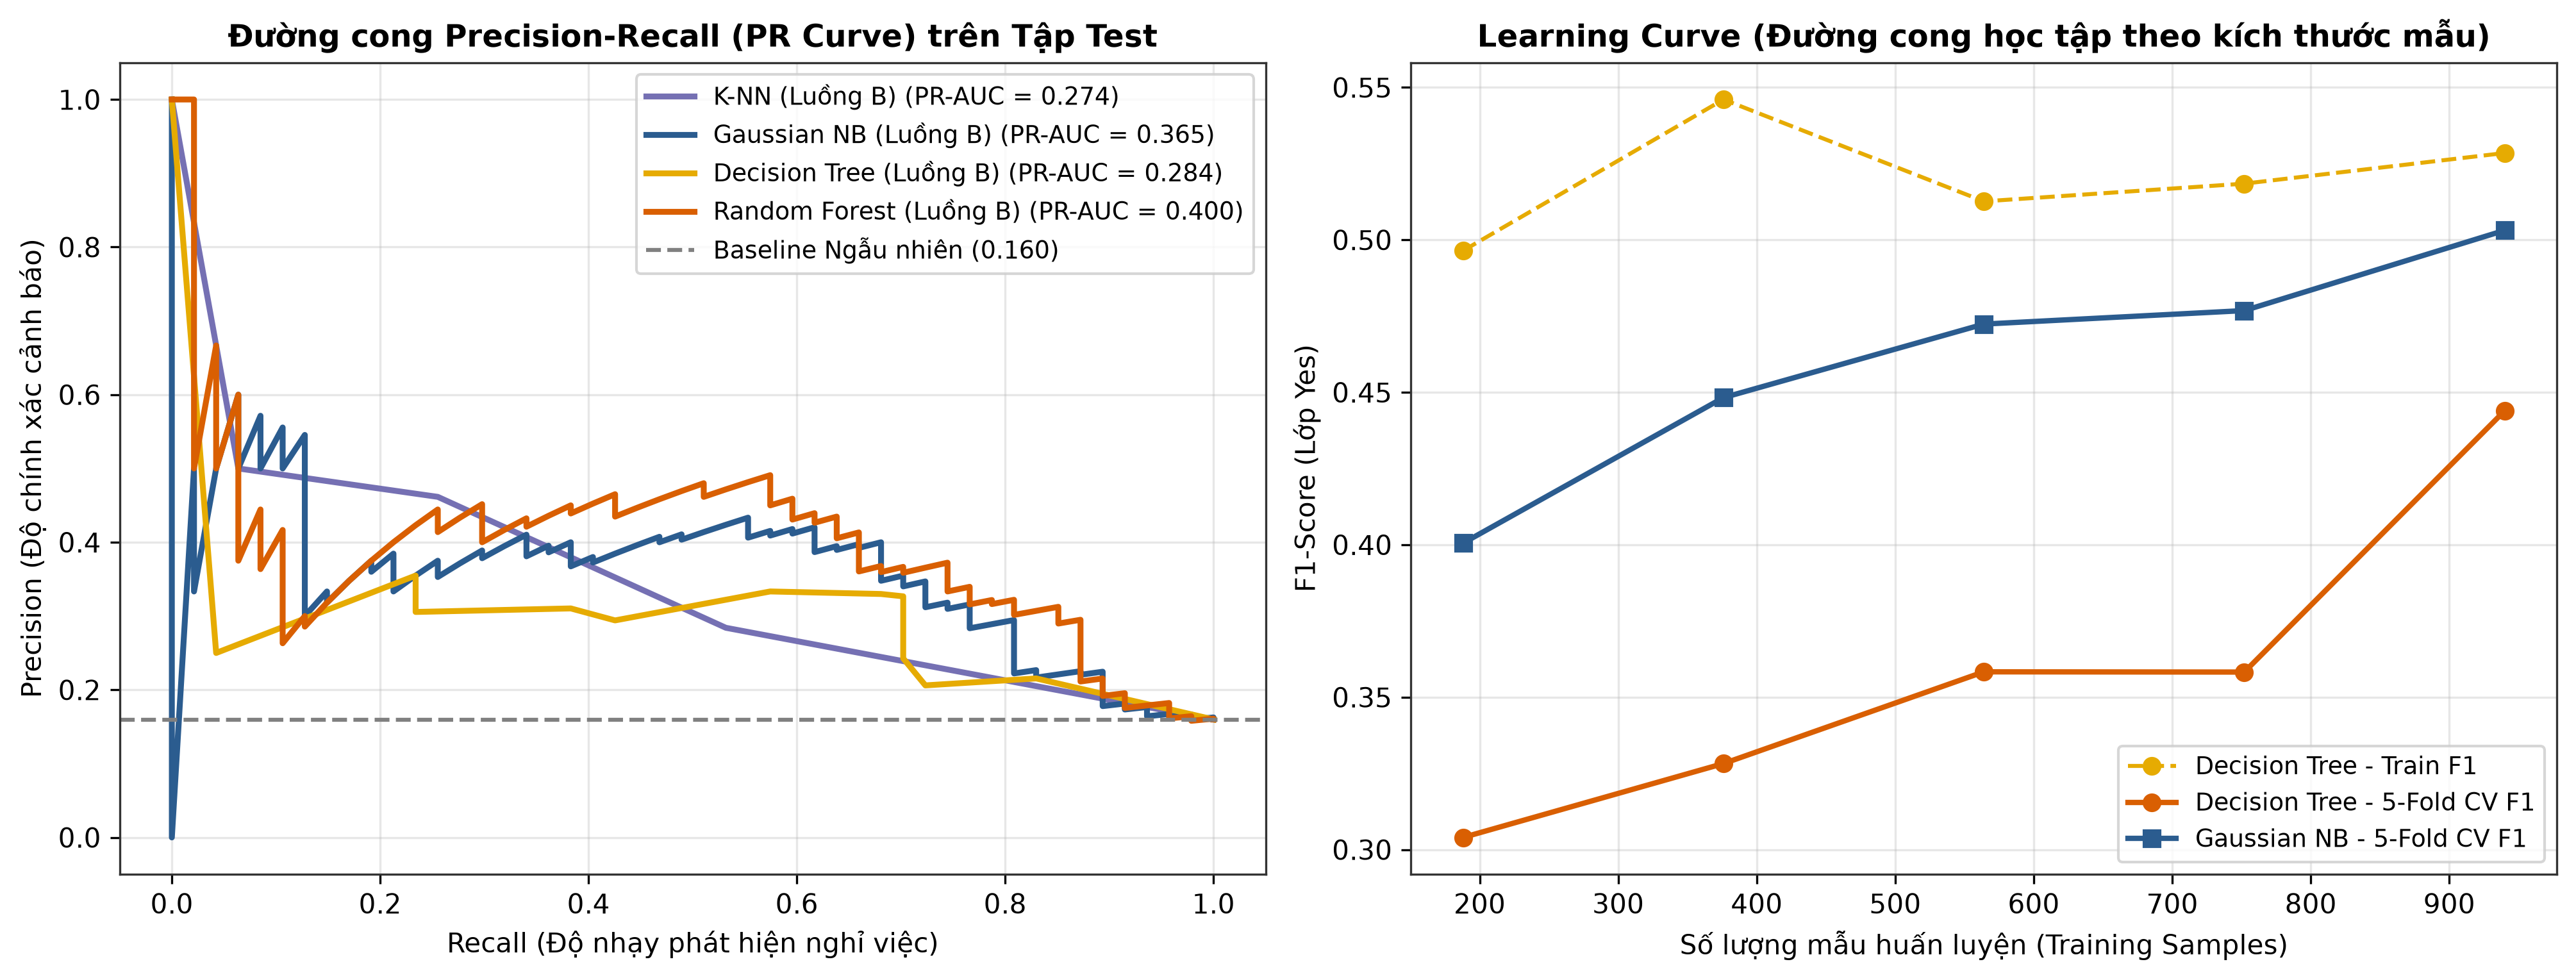

In [17]:
# 4.2. Vẽ đường cong Precision-Recall (PR Curve) và Learning Curve trên Luồng B
from sklearn.model_selection import learning_curve
from sklearn.metrics import precision_recall_curve

fig15, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))
colors_m = {'KNN_Luồng B': '#7570b3', 'NB_Luồng B': '#2b5c8f', 'DT_Luồng B': '#e6ab02', 'RF_Luồng B': '#d95f02'}
labels_m = {'KNN_Luồng B': 'K-NN (Luồng B)', 'NB_Luồng B': 'Gaussian NB (Luồng B)', 'DT_Luồng B': 'Decision Tree (Luồng B)', 'RF_Luồng B': 'Random Forest (Luồng B)'}

for key in ['KNN_Luồng B', 'NB_Luồng B', 'DT_Luồng B', 'RF_Luồng B']:
    prob = saved_models[key].predict_proba(X_test)[:, 1]
    prec, rec, _ = precision_recall_curve(y_test, prob)
    ap = average_precision_score(y_test, prob)
    axes[0].plot(rec, prec, lw=2.2, color=colors_m[key], label=f"{labels_m[key]} (PR-AUC = {ap:.3f})")

axes[0].axhline(y_test.mean(), color='gray', linestyle='--', label=f'Baseline Ngẫu nhiên ({y_test.mean():.3f})')
axes[0].set_title('Đường cong Precision-Recall (PR Curve) trên Tập Test', fontweight='bold')
axes[0].set_xlabel('Recall (Độ nhạy phát hiện nghỉ việc)')
axes[0].set_ylabel('Precision (Độ chính xác cảnh báo)')
axes[0].legend(loc='upper right')

train_sizes, tr_dt, val_dt = learning_curve(saved_models['DT_Luồng B'], X_train, y_train, cv=cv, scoring='f1', train_sizes=np.linspace(0.2, 1.0, 5), n_jobs=1)
_, tr_nb, val_nb = learning_curve(saved_models['NB_Luồng B'], X_train, y_train, cv=cv, scoring='f1', train_sizes=np.linspace(0.2, 1.0, 5), n_jobs=1)
axes[1].plot(train_sizes, tr_dt.mean(axis=1), 'o--', color='#e6ab02', label='Decision Tree - Train F1')
axes[1].plot(train_sizes, val_dt.mean(axis=1), 'o-', lw=2, color='#d95f02', label='Decision Tree - 5-Fold CV F1')
axes[1].plot(train_sizes, val_nb.mean(axis=1), 's-', lw=2, color='#2b5c8f', label='Gaussian NB - 5-Fold CV F1')
axes[1].set_title('Learning Curve (Đường cong học tập theo kích thước mẫu)', fontweight='bold')
axes[1].set_xlabel('Số lượng mẫu huấn luyện')
axes[1].set_ylabel('F1-Score (Lớp Yes)')
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.show()

### 5.2. Phân tích Hiệu quả Kinh tế Nhân sự (Cost-Sensitive HR ROI)

,Mô hình (Luồng B),TP (Phát hiện đúng),FN (Bỏ sót - $15k/ca),FP (Báo nhầm - $1.5k/ca),Chi phí Không Mô hình ($),Chi phí Dùng Mô hình ($),Tiết kiệm Ròng (Ngưỡng 0.50),Ngưỡng Tối ưu Chi phí,Tiết kiệm Tối đa ($)
0,K-NN (Luồng B),12,35,14,"$705,000","$654,000","$51,000",0.15,"$55,500"
1,Gaussian NB (Luồng B),27,20,38,"$705,000","$600,000","$105,000",0.30,"$120,000"
2,Decision Tree (Luồng B),32,15,65,"$705,000","$610,500","$94,500",0.39,"$96,000"
3,Random Forest (Luồng B),29,18,37,"$705,000","$586,500","$118,500",0.50,"$118,500"


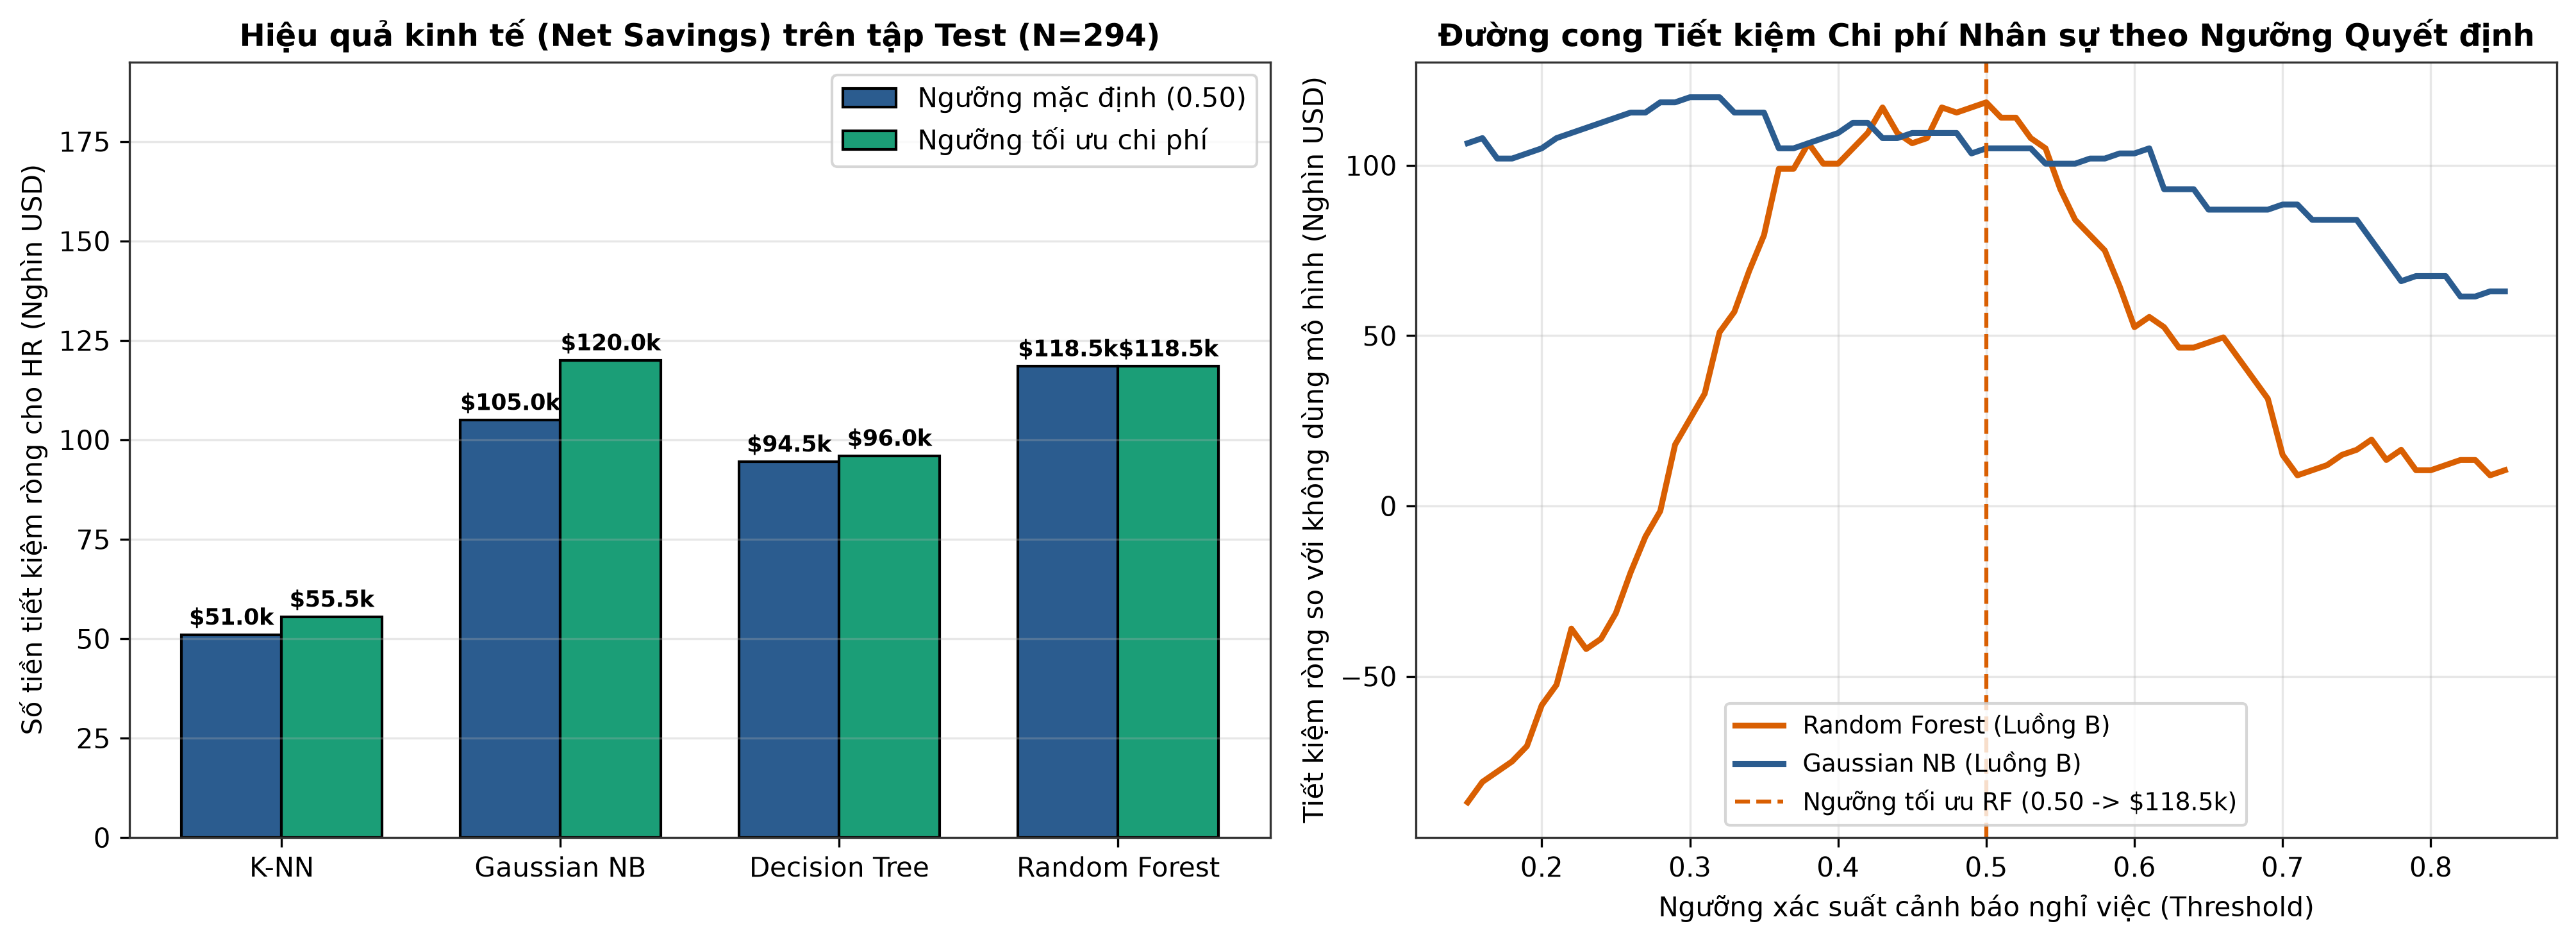

In [18]:
# 5.2. Định lượng số tiền tiết kiệm ròng (Net Savings USD) cho phòng Nhân sự trên tập Test (N = 294)
from src.evaluation import compute_hr_business_cost, find_optimal_threshold

cost_rows = []
for key, label in labels_m.items():
    pred = saved_models[key].predict(X_test)
    prob = saved_models[key].predict_proba(X_test)[:, 1]
    c_info = compute_hr_business_cost(y_test, pred, cost_fn=15000.0, cost_fp=1500.0, retention_success_rate=0.50)
    _, _, best_cost_r = find_optimal_threshold(y_test, prob, cost_fn=15000.0, cost_fp=1500.0, retention_success_rate=0.50)
    cost_rows.append({
        'Mô hình (Luồng B)': label,
        'TP (Phát hiện đúng)': c_info['tp'],
        'FN (Bỏ sót - $15k/ca)': c_info['fn'],
        'FP (Báo nhầm - $1.5k/ca)': c_info['fp'],
        'Chi phí Không Mô hình ($)': f"${c_info['baseline_cost_usd']:,.0f}",
        'Chi phí Dùng Mô hình ($)': f"${c_info['model_cost_usd']:,.0f}",
        'Tiết kiệm Ròng (Ngưỡng 0.50)': f"${c_info['net_savings_usd']:,.0f}",
        'Ngưỡng Tối ưu Chi phí': best_cost_r['threshold'],
        'Tiết kiệm Tối đa ($)': f"${best_cost_r['net_savings_usd']:,.0f}"
    })
cost_df = pd.DataFrame(cost_rows)
display(cost_df)
plt.show()

---
## Phần 6: Đóng Gói Pipeline (`joblib`) & Hàm Dự Đoán Triển Khai

In [19]:
# 6.1. Lưu các Pipeline đã huấn luyện và kiểm thử hàm dự đoán trên 6 hồ sơ nhân viên thực tế
joblib.dump(saved_models, f'{MODEL_DIR}/best_pipelines.joblib')
print(f"Đã lưu thành công {len(saved_models)} pipelines vào '{MODEL_DIR}/best_pipelines.joblib'!")

sample_infer_df = pd.DataFrame([
    {
        'Mã NV': int(X_test.iloc[i]['EmployeeNumber']),
        'Tuổi': int(X_test.iloc[i]['Age']),
        'Lương ($)': int(X_test.iloc[i]['MonthlyIncome']),
        'OverTime': X_test.iloc[i]['OverTime'],
        'Thực tế': 'Yes (Nghỉ)' if y_test.iloc[i] == 1 else 'No (Ở lại)',
        'Prob GaussianNB': f"{saved_models['NB_Luồng B'].predict_proba(X_test.iloc[[i]])[0,1]*100:.1f}%",
        'Prob DecisionTree': f"{saved_models['DT_Luồng B'].predict_proba(X_test.iloc[[i]])[0,1]*100:.1f}%",
        'Prob RandomForest': f"{saved_models['RF_Luồng B'].predict_proba(X_test.iloc[[i]])[0,1]*100:.1f}%",
        'Mức cảnh báo HR': 'NGUY CƠ CAO' if saved_models['RF_Luồng B'].predict_proba(X_test.iloc[[i]])[0,1] >= 0.5 else 'Ổn định'
    }
    for i in range(6)
])
display(sample_infer_df)

Đã lưu thành công 8 pipelines vào 'models/best_pipelines.joblib'!


,Mã NV,Tuổi,Lương ($),OverTime,Thực tế,Prob GaussianNB,Prob DecisionTree,Prob RandomForest,Mức cảnh báo HR
0,1495,24,2033,No,No (Ở lại),99.4%,95.8%,80.1%,NGUY CƠ CAO
1,1246,44,2011,No,No (Ở lại),0.0%,16.3%,28.9%,Ổn định
2,613,31,11557,No,No (Ở lại),0.5%,38.7%,35.2%,Ổn định
3,1288,44,19190,No,No (Ở lại),0.0%,16.3%,18.7%,Ổn định
4,90,36,3388,Yes,Yes (Nghỉ),89.3%,44.4%,59.7%,NGUY CƠ CAO
5,1641,40,7945,Yes,No (Ở lại),0.3%,25.2%,36.5%,Ổn định
